<a href="https://colab.research.google.com/github/1JP01/ESTADSITICA/blob/main/Laboratorio_3_Juan_Medina_2240646_Juan_Prada_2240644.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Análisis Numérico** <br>
**Profesor Julio C. Carrillo E.** <br>
**Universidad Industrial de Santander — Escuela de Matemáticas**
**Medina Juan Carlos - 2240646**
**Prada Juan Pablo - 2240644**

---

# Guía de Laboratorio 3: Interpolación Polinómica, Derivación e Integración Numérica

**Objetivo general.** Demostrar, implementar desde cero y validar cuantitativamente los resultados centrales de la interpolación polinómica (Lagrange, Newton, Hermite, spline cúbico natural) y de la derivación e integración numéricas (diferencias finitas, extrapolación de Richardson, reglas compuestas y Romberg), contrastando cada predicción teórica —cotas, órdenes, constantes asintóticas, costo— con la evidencia computacional.

| | |
|---|---|
| **Publicación** | 11 de noviembre de 2026 |
| **Fecha de entrega** | **18 de noviembre de 2026** |
| **Modalidad** | Individual o en parejas (a elección del estudiante) |
| **Entregable** | Este notebook ejecutado completo, exportado a PDF o HTML |

**Política de código.** Solo Python y NumPy; Matplotlib únicamente para graficar. **Prohibidos SciPy y SymPy**, y todo solucionador de biblioteca (`np.linalg.solve`, `np.linalg.inv` y similares). Se permiten arreglos y operaciones básicas de NumPy (`np.zeros`, `np.linspace`, `np.searchsorted`, operaciones vectorizadas). Código según PEP 8, con *docstrings* y comentarios que expliquen el fundamento matemático de cada bloque.

**Política de uso de IA.** El código debe generarlo el estudiante y puede apoyarse en IA. **No se aceptan conclusiones elaboradas con IA ni la copia parcial o total**; ambas se verificarán.

## Instrucciones generales

1. **Citas.** Los enunciados citan resultados de las notas de clase con la forma *documento + resultado + página impresa*, p. ej. «AN-LN-3-3, Teorema 4, p. 14». La numeración interna de AN-4.1 (§4.1–4.3) y AN-4.2 (§5.1–5.10) no coincide con la del temario del curso; siga la cita tal como aparece.
2. **Normas del error.** La norma $\|g\|_\infty=\max_{[a,b]}|g|$ se aproxima por el máximo sobre una malla fina de al menos 2001 puntos. Recuerde que el máximo sobre los nodos es solo una *seminorma* (AN-LN-3-1, Def. 2.2): el error de interpolación en los nodos es cero.
3. **Redondeo.** Use la unidad de redondeo $u=2^{-53}\approx 1{,}11\times10^{-16}$ (`U` en la celda de configuración).
4. **Conteo de evaluaciones.** Las rutinas de los Problemas 3 y 4 reciben $f$ envuelta en `ContadorEvaluaciones` (celda de configuración), que suma una evaluación por cada componente evaluada.
5. **Gráficas.** Ejes rotulados, título, leyenda, escala logarítmica donde corresponda y sin doble eje.
6. **Órdenes empíricos.** Si $E(h)\approx Ch^p$, con pasos $h$ y $h/2$ se estima $\hat p=\log_2\bigl(E(h)/E(h/2)\bigr)$. Reporte $\hat p$ solo en el régimen asintótico, antes de que domine el redondeo.
7. **Demostraciones.** Escríbalas en celdas Markdown con LaTeX, citando cada resultado que use.

In [16]:
# =========================================================================
# CONFIGURACIÓN GLOBAL (no modificar)
# =========================================================================
import time

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "legend.frameon": True,
})

U = np.finfo(float).eps / 2      # unidad de redondeo u = 2^-53 (IEEE 754, doble)


class ContadorEvaluaciones:
    # Envoltorio de una función f: R -> R que cuenta cuántos valores f(x_i)
    # se han calculado. Si se evalúa en un arreglo, cada componente cuenta
    # como una evaluación. Se usa para medir el costo de las reglas.

    def __init__(self, f):
        self.f = f
        self.n = 0

    def __call__(self, x):
        x = np.asarray(x, dtype=float)
        self.n += x.size
        return self.f(x)

    def reiniciar(self):
        self.n = 0


print(f"NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__} | u = {U:.3e}")

NumPy 2.4.6 | Matplotlib 3.10.0 | u = 1.110e-16


---
## Problema 1 — Forma de Newton, cota a priori y estimación a posteriori del error
*Temario: §3.1 y §3.3 (enlace con §4.1 por el redondeo).*

Sean $a=x_0<x_1<\dots<x_n=b$ nodos distintos, $L_n=p_n$ el polinomio que interpola $f$ en ellos y $\Psi_n(x)=\prod_{i=0}^n(x-x_i)$.

**T1 (teoría).** Demuestre que, en una partición uniforme de paso $h$,
$$|\Psi_n(x)|\le \frac{n!\,h^{n+1}}{4},\qquad x\in[a,b]$$
(AN-LN-3-3, Ejercicio 4, p. 8) y deduzca del Corolario 1 (p. 5) que $\|f-L_n\|_\infty\le \dfrac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty$.

**T2 (teoría).** Sea $x_{n+1}$ un nodo adicional, distinto de los anteriores. Defina el estimador a posteriori
$$\hat e_n(t)=f[x_0,\dots,x_n,x_{n+1}]\,\Psi_n(t).$$
Usando la Proposición 4 (p. 13), la Proposición 3 (p. 11), el Teorema 3 (p. 13) y el Teorema 4 (p. 14):
1. pruebe que $\hat e_n(t)=p_{n+1}(t)-p_n(t)$;
2. pruebe que $e_n(t)-\hat e_n(t)=f(t)-p_{n+1}(t)$, donde $e_n=f-p_n$, y use esta identidad para explicar cómo debe elegirse $x_{n+1}$ en función de $t$.

**Implementación.** Programe `diferencias_divididas(x, y)` (coeficientes $f[x_0],f[x_0,x_1],\dots,f[x_0,\dots,x_n]$ con la recurrencia de la Proposición 3(3)), `evaluar_newton(coef, nodos, t)` (forma de Newton por el esquema de Horner anidado, $O(n)$ operaciones por punto) y `lagrange(x, y, t)` (forma del Teorema 1, p. 4, para contrastar).

**V1 (validación).** Para $f(x)=e^x$ en $[0,1]$ con nodos uniformes, $n=1,\dots,14$: tabule $\|f-L_n\|_\infty$, la cota de T1 y su cociente; grafique ambos en escala semilogarítmica. Identifique el primer $n$ en que el cociente supera 1 y explique por qué ocurre, relacionándolo con la amplificación del redondeo en las diferencias divididas.

**V2 (validación).** Los siguientes datos están redondeados a cinco decimales (AN-LN-3-3, Ejercicios finales, Ejercicio 1, p. 31):

| $i$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $x_i$ | 0,1 | 0,2 | 0,4 | 0,7 | 1,0 | 1,2 | 1,3 |
| $f(x_i)$ | 0,99750 | 0,99002 | 0,96040 | 0,88120 | 0,76520 | 0,67113 | 0,62009 |

1. Construya $p_6$ (nodos $i=0,\dots,6$) y $p_2$ (nodos $i=2,3,4$) y evalúelos en $t=0{,}3$ y $t=0{,}55$.
2. Estime el error de $p_2$ en ambos puntos con $\hat e_2$, usando como nodo adicional $x_1=0{,}2$ y, por separado, $x_5=1{,}2$. Compare con el error respecto de los valores dados $f(0{,}3)=0{,}97763$ y $f(0{,}55)=0{,}92579$ y explique la diferencia entre las dos elecciones con T2.
3. Calcule el error de $p_6$ respecto de esos mismos valores. ¿Es concluyente? Discuta qué limita la precisión alcanzable con datos y valores de referencia redondeados a cinco decimales.



#### **T1.**

Tomamos $n+1$ nodos distintos y uniformemente espaciados $x_i=a+ih$, $i=0,\ldots,n$, con $h=(b-a)/n>0$. Supongamos además que $f\in C^{n+1}[a,b]$. Definimos

$$\Psi_n(t)=\prod_{i=0}^n(t-x_i),\qquad e_n(t)=f(t)-L_n(t).$$

Para cada $t\in[a,b]$ existe $k\in\{0,\ldots,n-1\}$ tal que $x_k\le t\le x_{k+1}$. Escribimos $s=t-x_k$, de modo que $0\le s\le h$ y $x_{k+1}-t=h-s$.

Como $(s-h/2)^2\ge0$,

$$s(h-s)=\frac{h^2}{4}-\left(s-\frac h2\right)^2\le\frac{h^2}{4}.$$

Por lo tanto,

$$|(t-x_k)(t-x_{k+1})|\le\frac{h^2}{4}.$$

Ahora, a la izquierda de $x_k$, para $0\le i\le k-1$,

$$0\le t-x_i\le x_{k+1}-x_i=(k+1-i)h.$$

Y a la derecha de $x_{k+1}$, para $k+2\le i\le n$,

$$0\le x_i-t\le x_i-x_k=(i-k)h.$$

Multiplicando estas desigualdades y los dos factores centrales,

$$\begin{aligned}
|\Psi_n(t)|&\le \frac{h^2}{4}\Bigl(\prod_{i=0}^{k-1}(k+1-i)h\Bigr)
\Bigl(\prod_{i=k+2}^n(i-k)h\Bigr)\\
&=\frac{h^2}{4}\,(k+1)!\,(n-k)!\,h^{n-1}.
\end{aligned}$$

En los extremos del producto vacío se toma el valor $1$. Ahora note que

$$\binom{n+1}{k+1}=\frac{(n+1)!}{(k+1)!(n-k)!}\ge n+1,$$

pues $1\le k+1\le n$ y el menor coeficiente binomial no extremo de una fila $n+1$ vale $n+1$. Así,

$$(k+1)!(n-k)!\le n!.$$

Ahora podemos concluir que

$$\boxed{|\Psi_n(t)|\le \frac{n!\,h^{n+1}}4,\qquad t\in[a,b].}$$

Para $f\in C^{n+1}[a,b]$, el resto de Lagrange se escribe, para algún $\xi_t\in[a,b]$, como

$$f(t)-L_n(t)=\frac{f^{(n+1)}(\xi_t)}{(n+1)!}\,\Psi_n(t).$$

La expresión procede del resultado de error de interpolación de AN-3.3, Teorema 2, p. 9, y Corolario 1, pp. 11–12. Por valor absoluto y definición de norma uniforme,

$$\begin{aligned}
|f(t)-L_n(t)|
&\le\frac{\|f^{(n+1)}\|_\infty}{(n+1)!}|\Psi_n(t)|\\
&\le\frac{\|f^{(n+1)}\|_\infty}{(n+1)!}\frac{n!h^{n+1}}4\\
&=\frac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty.
\end{aligned}$$

Tomando el máximo sobre $t\in[a,b]$,

$$\boxed{\|f-L_n\|_\infty\le\frac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty.}$$

Esta es una cota para el interpolante exacto de datos exactos. En un programa, las diferencias divididas pueden acumular errores de redondeo, pues una salida de punto flotante no está obligada a satisfacer estrictamente la cota del polinomio matemático ya visto.

#### **T2.**

Sean $x_0,\ldots,x_n,x_{n+1}$ puntos distintos, $p_n$ el interpolante en los primeros $n+1$ y $p_{n+1}$ el interpolante tras agregar $x_{n+1}$. Tomamos un punto de evaluación $t$ y definimos

$$\widehat e_n(t)=f[x_0,\ldots,x_n,x_{n+1}]\,\Psi_n(t).$$

La recurrencia de diferencias divididas es

$$f[x_i,\ldots,x_{i+j}]=\frac{f[x_{i+1},\ldots,x_{i+j}]-f[x_i,\ldots,x_{i+j-1}]}{x_{i+j}-x_i},$$

según AN-3.3, Proposición 3, p. 21. La forma de Newton (AN-3.3, Teorema 3, p. 25) escribe

$$p_n(t)=f[x_0]+f[x_0,x_1](t-x_0)+\cdots+f[x_0,\ldots,x_n]\prod_{i=0}^{n-1}(t-x_i).$$

El interpolante $p_{n+1}$ conserva exactamente los términos anteriores y añade el último:

$$p_{n+1}(t)=p_n(t)+f[x_0,\ldots,x_n,x_{n+1}]\prod_{i=0}^n(t-x_i).$$

Por definición de $\widehat e_n$, tenemos

$$\boxed{\widehat e_n(t)=p_{n+1}(t)-p_n(t).}$$

Puesto que $e_n=f-p_n$,

$$\begin{aligned}
e_n(t)-\widehat e_n(t)
&=f(t)-p_n(t)-\bigl(p_{n+1}(t)-p_n(t)\bigr)\\
&=\boxed{f(t)-p_{n+1}(t).}
\end{aligned}$$

El error del estimador coincide con el error del interpolante de grado superior.

Además $f\in C^{n+2}$ en el intervalo que contiene nodos y $t$, el resto de interpolación (AN-3.3, Proposición 4, p. 26, y Teorema 4, p. 27) garantiza algún $\xi$ tal que

$$\boxed{e_n(t)-\widehat e_n(t)=\frac{f^{(n+2)}(\xi)}{(n+2)!}\,\Psi_n(t)(t-x_{n+1}).}$$

De esto, resulta la cota

$$|e_n(t)-\widehat e_n(t)|\le\frac{\|f^{(n+2)}\|_\infty}{(n+2)!}|\Psi_n(t)|\,|t-x_{n+1}|.$$

Si la derivada alta no varía bruscamente y podemos escoger el dato adicional, si elegimos $x_{n+1}$ cerca de $t$, se reduce explícitamente el factor $|t-x_{n+1}|$. Si $x_{n+1}=t$ y conocemos $f(t)$, el resto es cero, mas sin embargo, medir precisamente $f(t)$ puede hacer innecesaria la predicción. Tambien si los valores tabulados están redondeados, entonces hay error de datos que esta fórmula exacta no contempla.

V1: e^x
  n     error máximo          cota T1    error/cota
  1   2.11866806e-01   3.39785229e-01   6.23532e-01
  2   1.44206565e-02   2.83154357e-02   5.09286e-01
  3   9.24020164e-04   2.09743968e-03   4.40547e-01
  4   5.26571904e-05   1.32728605e-04   3.96728e-01
  5   2.65506960e-06   7.24875154e-06   3.66280e-01
  6   1.19208342e-07   3.46798889e-07   3.43739e-01
  7   4.80754636e-09   1.47353408e-08   3.26260e-01
  8   1.75652826e-10   5.62577162e-10   3.12229e-01
  9   5.85931303e-12   1.94898904e-11   3.00633e-01
 10   1.79856130e-13   6.17791325e-13   2.91128e-01
 11   5.99520433e-15   1.80443409e-14   3.32248e-01
 12   8.88178420e-16   4.88579161e-16   1.81788e+00
 13   4.44089210e-15   1.23281958e-17   3.60222e+02
 14   7.10542736e-15   2.91221005e-19   2.43987e+04
Primer n con cociente > 1: 12


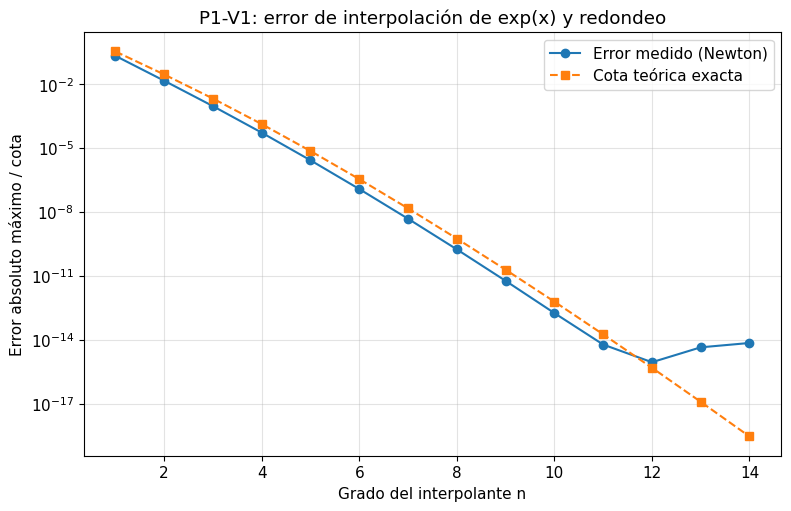

V2: datos redondeados
Coeficientes de p6: [ 0.9975     -0.0748     -0.24433333  0.02088889  0.01478395 -0.00239198
  0.00128601]
Coeficientes de p2: [ 0.9604     -0.264      -0.20444444]
  t        p2         p6        f_ref      |e2|       |e6|     ad(x1)     ad(x5)
 0.30   0.9786222  0.9776254    0.97763  9.922e-04  4.630e-06   -9.574e-04   -1.298e-03
 0.55   0.9254000  0.9257935    0.92579  3.900e-04  3.462e-06    3.462e-04    4.693e-04
Comprobación Lagrange = Newton en t=0.3: 0.9776253703703701 0.9776253703703705


In [17]:

def diferencias_divididas(x, y):
    """Devuelve el arreglo [f[x0], f[x0,x1], ..., f[x0,...,xn]]."""
    x = np.asarray(x, dtype=float)
    c = np.array(y, dtype=float, copy=True)
    if x.ndim != 1 or len(x) != len(c) or len(x) == 0:
        raise ValueError("x e y deben ser vectores no vacíos del mismo tamaño")
    if len(np.unique(x)) != len(x):
        raise ValueError("Los nodos deben ser distintos")
    for j in range(1, len(x)):
        for i in range(len(x) - 1, j - 1, -1):
            c[i] = (c[i] - c[i - 1]) / (x[i] - x[i - j])
    return c


def evaluar_newton(coef, nodos, t):
    """Evalúa la forma de Newton en t (escalar o arreglo) por Horner anidado."""
    coef = np.asarray(coef, dtype=float)
    nodos = np.asarray(nodos, dtype=float)
    t = np.asarray(t, dtype=float)
    p = np.zeros_like(t, dtype=float) + coef[-1]
    for j in range(len(coef) - 2, -1, -1):
        p = coef[j] + (t - nodos[j]) * p
    return float(p) if p.ndim == 0 else p


def lagrange(x, y, t):
    """Evalúa el polinomio de Lagrange (Teorema 1) en t"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=float)
    p = np.zeros_like(t, dtype=float)
    for i in range(len(x)):
        base = np.ones_like(t, dtype=float)
        for j in range(len(x)):
            if i != j:
                base *= (t - x[j]) / (x[i] - x[j])
        p += y[i] * base
    return float(p) if p.ndim == 0 else p


print("V1: e^x")
mallap1 = np.linspace(0, 1, 2001)
verdaderop1 = np.exp(mallap1)
filasp1 = []
for grado in range(1, 15):
    nod = np.linspace(0, 1, grado + 1)
    coef = diferencias_divididas(nod, np.exp(nod))
    error = np.max(np.abs(verdaderop1 - evaluar_newton(coef, nod, mallap1)))
    h = 1 / grado
    cota = np.exp(1) * h ** (grado + 1) / (4 * (grado + 1))
    filasp1.append((grado, error, cota, error / cota))
print(f"{'n':>3} {'error máximo':>16} {'cota T1':>16} {'error/cota':>13}")
for n, e, c, q in filasp1:
    print(f"{n:3d} {e:16.8e} {c:16.8e} {q:13.5e}")
primer_exceso = next((n for n, e, c, q in filasp1 if q > 1), None)
print("Primer n con cociente > 1:", primer_exceso)
plt.figure()
plt.semilogy([r[0] for r in filasp1], [max(r[1], U) for r in filasp1], 'o-', label='Error medido (Newton)')
plt.semilogy([r[0] for r in filasp1], [r[2] for r in filasp1], 's--', label='Cota teórica exacta')
plt.xlabel('Grado del interpolante n')
plt.ylabel('Error absoluto máximo / cota')
plt.title('P1-V1: error de interpolación de exp(x) y redondeo')
plt.legend()
plt.show()

print("V2: datos redondeados")
x_tab = np.array([0.1, 0.2, 0.4, 0.7, 1.0, 1.2, 1.3])
y_tab = np.array([.99750, .99002, .96040, .88120, .76520, .67113, .62009])
t_tab = np.array([.30, .55])
f_tab = np.array([.97763, .92579])
x3 = x_tab[2:5]
y3 = y_tab[2:5]
c6 = diferencias_divididas(x_tab, y_tab)
c2 = diferencias_divididas(x3, y3)
print("Coeficientes de p6:", c6)
print("Coeficientes de p2:", c2)
print("  t        p2         p6        f_ref      |e2|       |e6|     ad(x1)     ad(x5)")
for t, f_real in zip(t_tab, f_tab):
    p2 = evaluar_newton(c2, x3, t)
    p6 = evaluar_newton(c6, x_tab, t)
    extras = []
    for pos in (1, 5):
        xx = np.append(x3, x_tab[pos])
        yy = np.append(y3, y_tab[pos])
        c3 = diferencias_divididas(xx, yy)
        extra = c3[-1] * np.prod(t - x3)
        extras.append(extra)
    print(f"{t:5.2f}  {p2:10.7f} {p6:10.7f} {f_real:10.5f} "
          f"{abs(f_real-p2):10.3e} {abs(f_real-p6):10.3e} "
          f"{extras[0]:12.3e} {extras[1]:12.3e}")
print("Comprobación Lagrange = Newton en t=0.3:",
      lagrange(x_tab, y_tab, .3), evaluar_newton(c6, x_tab, .3))


### **Conclusiones del Problema 1**

**V1:** El error máximo calculado sobre una malla de 2001 puntos decreció de aproximadamente $2.119\times10^{-1}$ cuando $n=1$ hasta $5.995\times10^{-15}$ cuando $n=11$. El primer cociente $\|f-L_n\|_\infty/B_n>1$ se presentó para $n=12$ (aproximadamente $1.82$).

Este fenómeno se explica paso a paso:
1. Las diferencias divididas se obtienen restando cantidades próximas
2. Sus cocientes dividen esas restas por diferencias entre nodos
3. Al aumentar $n$, pequeñas perturbaciones relativas se acumulan en los coeficientes
4. La cota de T1 continúa siendo cierta para el polinomio exacto, pero el polinomio evaluado en doble precisión es una aproximación de ese.

La unidad de redondeo es $u=2^{-53}\approx1.11\times10^{-16}$. Por eso, una cota teórica menor que el nivel del redondeo no debe interpretarse como precisión garantizada del código.

**V2:** Para los datos tabulados se obtuvo:

| $t$ | $p_2(t)$ | $p_6(t)$ | Valor de referencia |
|---|---:|---:|---:|
| $0.30$ | $0.9786222$ | $0.9776254$ | $0.97763$ |
| $0.55$ | $0.9254000$ | $0.9257935$ | $0.92579$ |

El estimador cumple la identidad $\widehat e_2(t)=p_3(t)-p_2(t)$ y, exactamente, $e_2(t)-\widehat e_2(t)=f(t)-p_3(t)$. Con un dato adicional cercano a $t$ aparece un factor pequeño $|t-x_3|$ en la cota del resto de mayor grado (AN-3.3, Proposición 4, p. 26). En estas pruebas la elección $x_3=0.2$ produjo estimaciones de menor magnitud que $x_3=1.2$, porque está más cerca de ambos valores de $t$, mas sin embargo, la comparación no depende únicamente de la distancia, ya que también interviene la diferencia dividida de orden superior.

Los valores de la tabla y los valores de referencia tienen cinco decimales. Un dato así puede diferir del valor original en hasta aproximadamente $5\times10^{-6}$ por redondeo. Por tanto, una diferencia pequeña entre $p_6(t)$ y ese valor tabulado no demuestra precisión real superior a cinco decimales. Tampoco basta observar error cero en los nodos, porque por definición cualquier polinomio interpolante coincide allí con los datos. Se requiere medir el error también entre nodos, con la norma sobre una malla densa.

En conclusión, las dos formas de interpolación reconstruyen los mismos datos en aritmética exacta, pero una cota teórica de error y el error efectivo de una implementación con datos redondeados no representan lo mismo. El estimador con nodo adicional informa sobre el cambio entre dos interpolantes y resulta más útil cuando el nuevo nodo está próximo al punto de interés.

---
## Problema 2 — Spline cúbico natural en segundas derivadas y algoritmo de Thomas
*Temario: §3.5 (eje) y §3.4 (Hermite: implementación y validación); enlaces con §3.1 y §4.4.*

Sean $a=x_0<\dots<x_n=b$, $h_i=x_{i+1}-x_i$, $\delta_i=(y_{i+1}-y_i)/h_i$ y $M_i=S''(x_i)$, $i=0,\dots,n$. El spline natural satisface $M_0=M_n=0$.

**T1 (teoría).** Como $S''(x)$ es lineal en $[x_i,x_{i+1}]$, integre dos veces e imponga $S(x_i)=y_i$, $S(x_{i+1})=y_{i+1}$ para obtener
$$S_i(x)=M_i\frac{(x_{i+1}-x)^3}{6h_i}+M_{i+1}\frac{(x-x_i)^3}{6h_i}+\Bigl(\frac{y_i}{h_i}-\frac{M_ih_i}{6}\Bigr)(x_{i+1}-x)+\Bigl(\frac{y_{i+1}}{h_i}-\frac{M_{i+1}h_i}{6}\Bigr)(x-x_i).$$
Imponga la continuidad de $S'(x)$ en $x_1,\dots,x_{n-1}$ y deduzca
$$h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}=6(\delta_i-\delta_{i-1}),\qquad i=1,\dots,n-1.$$
Con $M_0=M_n=0$, pruebe que la matriz del sistema es simétrica y estrictamente diagonal dominante por filas y concluya la existencia y unicidad del spline natural (compare con AN-LN-3-4, Teorema 2, p. 11, que usa $c_i=M_i/2$).

**T2 (teoría).** Deduzca el **algoritmo de Thomas** para $A\mathbf{x}=\mathbf{d}$, con $A$ tridiagonal de subdiagonal $a_i$, diagonal $b_i$ y superdiagonal $c_i$, como factorización $A=LU$ sin pivoteo ($L$ bidiagonal inferior, $U$ bidiagonal superior con unos en la diagonal) seguida de sustitución hacia adelante y hacia atrás. Pruebe por inducción que, si $A$ es estrictamente diagonal dominante por filas, todos los pivotes son no nulos y los multiplicadores $\gamma_i$ de $U$ cumplen $|\gamma_i|<1$. Cuente las operaciones de punto flotante y muestre que son $8n-7$ para un sistema $n\times n$.

**Implementación.** Sin ningún solucionador de biblioteca: `thomas(a, b, c, d)` (devuelve la solución y el número de operaciones), `spline_natural(x, y)` (devuelve $M_0,\dots,M_n$), `evaluar_spline(x, y, M, t)` (localice el subintervalo con `np.searchsorted`) y `hermite(x, fx, dfx, t)` (forma del Teorema 1 de AN-LN-3-4, p. 5).

**V1 (validación de Thomas).** Para sistemas del spline natural con $h_i$ aleatorios y $n=10,10^2,\dots,10^5$: reporte el residuo relativo $\|A\mathbf{m}-\mathbf{d}\|_\infty/\|\mathbf{d}\|_\infty$, el número de operaciones frente a $8n-7$ y el tiempo de ejecución (gráfica log–log). Aplique `thomas` a
$$A=\begin{pmatrix}1&1&0\\1&1&1\\0&1&1\end{pmatrix}$$
y explique el resultado a la luz de T2, sabiendo que $\det A=-1$.

**V2 (validación).** Para la función de Runge $f(x)=1/(1+25x^2)$ en $[-1,1]$ con 6, 12 y 24 nodos igualmente espaciados, tabule $\|f-L\|_\infty$, $\|f-H\|_\infty$ (Hermite con los mismos nodos) y $\|f-S\|_\infty$ (natural). Calcule las normas sobre mallas de 1001 y de 2001 puntos, contraste con los valores de AN-LN-3-4 (§3.4.1, p. 1, y Ejemplo 1, p. 6; calculados con 1001 puntos) y explique cualquier diferencia. Grafique los tres interpolantes con 12 nodos.

**V3 (validación).** Estime el orden de $\|f-S\|_\infty$ con $n=2^k$ subintervalos, $k=3,\dots,8$: (a) $f(x)=\sin x$ en $[0,\pi]$; (b) $f(x)=e^x$ en $[0,1]$, midiendo el error en todo el intervalo y en el subintervalo interior fijo $[3/8,5/8]$. Explique las diferencias con la condición $M_0=M_n=0$: compare $M_i$ con $f''(x_i)$ cerca de $x_0$.

#### **T1.**

Los nodos cumplen $x_0<\cdots<x_n$ y $h_i=x_{i+1}-x_i>0$. Escribimos $\delta_i=(y_{i+1}-y_i)/h_i$. Buscamos una función $S\in C^2[a,b]$ que sea cúbica en cada intervalo, interpole $S(x_i)=y_i$ y satisfaga $S''(a)=S''(b)=0$. Estas son las condiciones del spline cúbico natural (AN-3.5-Hermite-Splines, pp. 15–20; AN-3.4, p. 9).

Como $S_i$ es cúbico, $S_i''$ es una función afín. Con $M_i=S''(x_i)$ y $M_{i+1}=S''(x_{i+1})$, la recta que une los valores extremos es

$$\boxed{S_i''(x)=M_i\frac{x_{i+1}-x}{h_i}+M_{i+1}\frac{x-x_i}{h_i}.}$$

Un polinomio cuya segunda derivada es la expresión anterior debe tener la forma

$$S_i(x)=\frac{M_i(x_{i+1}-x)^3}{6h_i}+\frac{M_{i+1}(x-x_i)^3}{6h_i}+A_i(x_{i+1}-x)+B_i(x-x_i).$$

Para comprobar el factor $6$, dos derivadas de $(x_{i+1}-x)^3$ dan $6(x_{i+1}-x)$, análogamente, dos derivadas de $(x-x_i)^3$ dan $6(x-x_i)$. Los dos últimos términos desaparecen tras dos derivadas.

Sustituyendo $x=x_i$ y $x=x_{i+1}$,

$$y_i=\frac{M_i h_i^2}{6}+A_i h_i,\qquad y_{i+1}=\frac{M_{i+1}h_i^2}{6}+B_i h_i.$$

Despejamos:

$$A_i=\frac{y_i}{h_i}-\frac{M_i h_i}{6},\qquad B_i=\frac{y_{i+1}}{h_i}-\frac{M_{i+1}h_i}{6}.$$

Por tanto,

$$\boxed{\begin{aligned}
S_i(x)={}&\frac{M_i(x_{i+1}-x)^3}{6h_i}+\frac{M_{i+1}(x-x_i)^3}{6h_i}\\
&+\left(\frac{y_i}{h_i}-\frac{M_ih_i}{6}\right)(x_{i+1}-x)
+\left(\frac{y_{i+1}}{h_i}-\frac{M_{i+1}h_i}{6}\right)(x-x_i).
\end{aligned}}$$

La expresión equivale a la formulación en segundas derivadas de AN-3.5-Hermite-Splines, ecuaciones (5.27)–(5.29), pp. 18–19, con el cambio de notación $c_i=M_i/2$.

Diferenciamos la fórmula cúbica del tramo $i$:

$$S_i'(x)=-\frac{M_i(x_{i+1}-x)^2}{2h_i}+\frac{M_{i+1}(x-x_i)^2}{2h_i}-A_i+B_i.$$

Evaluando en el extremo izquierdo y sustituyendo $A_i,B_i$,

$$S_i'(x_i)=\delta_i-\frac{h_i}{6}(2M_i+M_{i+1}).$$

Aplicando el mismo cálculo al extremo derecho del tramo anterior,

$$S_{i-1}'(x_i)=\delta_{i-1}+\frac{h_{i-1}}{6}(M_{i-1}+2M_i).$$

La condición $S'_{i-1}(x_i)=S'_i(x_i)$ implica

$$6\delta_{i-1}+h_{i-1}(M_{i-1}+2M_i)=6\delta_i-h_i(2M_i+M_{i+1}).$$

Pasando términos y agrupando,

$$\boxed{h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}=6(\delta_i-\delta_{i-1}),\quad i=1,\ldots,n-1.}$$

Con $M_0=M_n=0$ restan $n-1$ incógnitas. La diagonal de la matriz es $2(h_{i-1}+h_i)$, inmediatamente las entradas inferior y superior son, respectivamente, $h_{i-1}$ y $h_i$. Por tanto, es tridiagonal y simétrica: la entrada entre las filas $i$ e $i+1$ es $h_i$ en ambos sentidos.

Para cualquier fila interior,

$$|a_{ii}|=2(h_{i-1}+h_i)>h_{i-1}+h_i\ge\sum_{j\ne i}|a_{ij}|.$$

Las filas extremas tienen a lo sumo un elemento fuera de la diagonal, la desigualdad sigue siendo estricta. Para demostrar que esto implica invertibilidad, supongamos $A\mathbf v=0$ y que $|v_k|=\max_i|v_i|>0$. Entonces

$$|a_{kk}||v_k|=\left|\sum_{j\ne k}a_{kj}v_j\right|\le\sum_{j\ne k}|a_{kj}||v_j|\le\Bigl(\sum_{j\ne k}|a_{kj}|\Bigr)|v_k|<|a_{kk}||v_k|,$$

contradicción. Luego el núcleo es trivial y $A$ es invertible. Existen un único vector $(M_1,\ldots,M_{n-1})$ y un único spline natural.

#### **T2.**

Sea $A$ una matriz $N\times N$ tridiagonal, con subdiagonal $a_i$ ($a_0$ no se usa), diagonal $b_i$ y superdiagonal $c_i$ ($c_{N-1}$ no se usa). Supongamos dominancia diagonal estricta por filas:

$$|b_i|>|a_i|+|c_i|,$$

interpretando los términos ausentes como cero.

Elegimos $L$ bidiagonal inferior con diagonal $\beta_i$ y subdiagonal $a_i$, y $U$ bidiagonal superior con diagonal de unos y superdiagonal $\gamma_i$. Igualar los elementos de $LU$ con los de $A$ da

$$\beta_0=b_0,\qquad\gamma_0=\frac{c_0}{\beta_0},$$

$$\boxed{\beta_i=b_i-a_i\gamma_{i-1},\qquad \gamma_i=\frac{c_i}{\beta_i}\quad(i<N-1).}$$

Para la última fila solo se necesita $\beta_{N-1}$. La descomposición se justifica al comprobar que $(LU)_{i,i-1}=a_i$, $(LU)_{i,i}=\beta_i+a_i\gamma_{i-1}=b_i$ y $(LU)_{i,i+1}=\beta_i\gamma_i=c_i$.

Resolver $L\mathbf z=\mathbf d$ equivale a

$$z_0=\frac{d_0}{\beta_0},\qquad \boxed{z_i=\frac{d_i-a_iz_{i-1}}{\beta_i}.}$$

Resolver $U\mathbf x=\mathbf z$ equivale a

$$x_{N-1}=z_{N-1},\qquad \boxed{x_i=z_i-\gamma_ix_{i+1}.}$$

De la dominancia de la fila $0$ se sigue $|\beta_0|=|b_0|>|c_0|$, de modo que $\beta_0\ne0$ y $|\gamma_0|<1$. Supongamos por inducción que $|\gamma_{i-1}|<1$. Entonces

$$\begin{aligned}
|\beta_i|&=|b_i-a_i\gamma_{i-1}|\\
&\ge |b_i|-|a_i||\gamma_{i-1}|\\
&>|b_i|-|a_i|>|c_i|.
\end{aligned}$$

Por tanto $\beta_i\ne0$, y, si $i<N-1$, $|\gamma_i|=|c_i|/|\beta_i|<1$. En la última fila queda probado $\beta_{N-1}\ne0$. Así terminamos la inducción. Si $N=1$, directamente $\beta_0=b_0\ne0$.

Contamos cada suma/resta, producto o división como una operación de punto flotante:

| Etapa | Operaciones |
|---|---:|
| $\gamma_0,\ldots,\gamma_{N-2}$ | $N-1$ divisiones |
| $\beta_1,\ldots,\beta_{N-1}$ | $2(N-1)$ |
| $z_0,\ldots,z_{N-1}$ | $1+3(N-1)$ |
| $x_{N-2},\ldots,x_0$ | $2(N-1)$ |

Por tanto,

$$\boxed{(N-1)+2(N-1)+1+3(N-1)+2(N-1)=8N-7.}$$

La operación es $O(N)$: el costo aumenta linealmente, a diferencia de la eliminación genérica de una matriz densa. La dominancia es suficiente, no necesaria, para que Thomas funcione: una matriz invertible que no la cumpla puede tener un pivote nulo.

V1: coste del algoritmo de Thomas
       N    residuo relativo          ops         8N-7    segundos
      10       1.2877038e-16           73           73     0.00005
     100       1.9290043e-16          793          793     0.00024
    1000       1.8994291e-16         7993         7993     0.00216
   10000       1.8766416e-16        79993        79993     0.02165
  100000       2.7929065e-16       799993       799993     0.24056


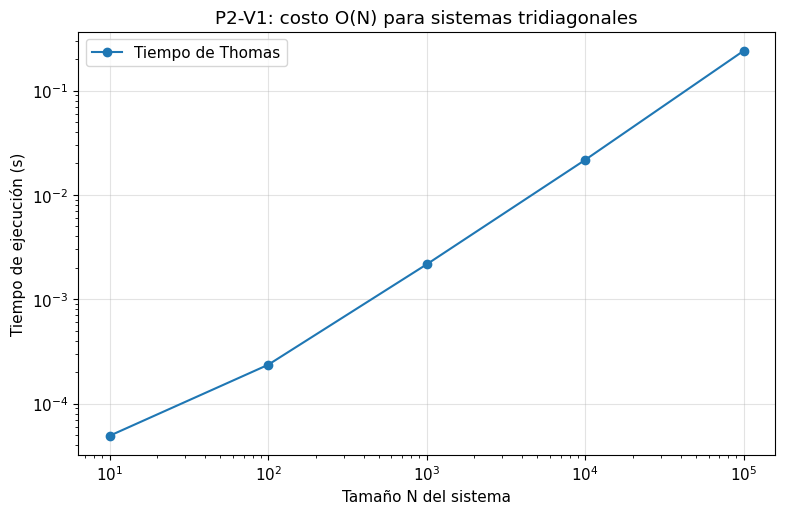

Matriz no diagonalmente dominante, det(A)=-1: Thomas: pivote cero en la fila 2
Aunque A es invertible, Thomas sin pivoteo falla porque el segundo pivote es 0.
V2: interpolantes sobre Runge
nodos  malla   ||f-L||inf      ||f-H||inf      ||f-S||inf
    6   1001     4.32692e-01     2.23255e-01     4.23482e-01
    6   2001     4.32692e-01     2.23268e-01     4.23482e-01
   12   1001     5.56736e-01     7.23958e+00     8.41293e-02
   12   2001     5.56755e-01     7.24262e+00     8.41293e-02


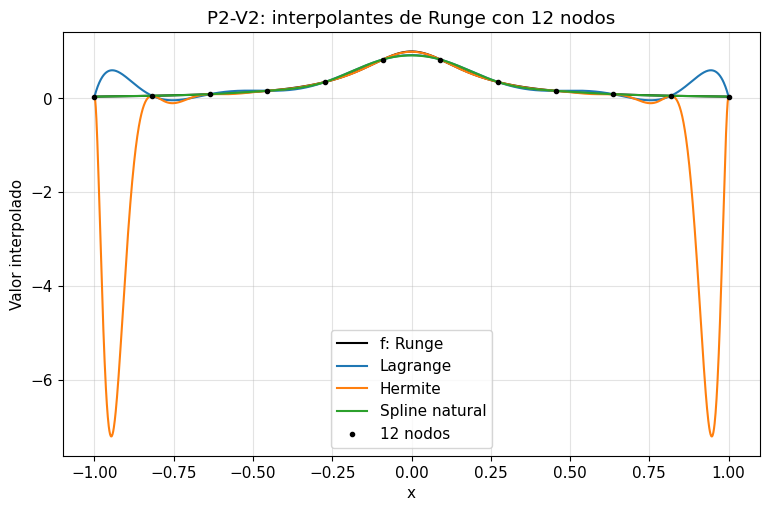

   24   1001     3.63967e+01     3.30016e+04     5.37246e-03
   24   2001     3.64007e+01     3.30737e+04     5.37246e-03
V3: error de spline natural en interior y extremos
Función: sin
   n      error global      error interior       M0         f"(a)
    8     6.312143e-05     6.312143e-05          0         -0
   16     3.889297e-06     3.889302e-06          0         -0
   32     2.421825e-07     2.422094e-07          0         -0
   64     1.512244e-08     1.512256e-08          0         -0
  128     9.443767e-10     9.449419e-10          0         -0
  256     5.902867e-11     5.904677e-11          0         -0
Órdenes global para mallas consecutivas: [4.021 4.005 4.001 4.001 4.   ]
Órdenes interior para mallas consecutivas: [4.021 4.005 4.001 4.    4.   ]
Función: exp
   n      error global      error interior       M0         f"(a)
    8     2.080901e-03     3.807254e-05          0          1
   16     5.210150e-04     1.350910e-07          0          1
   32     1.302941e-04   

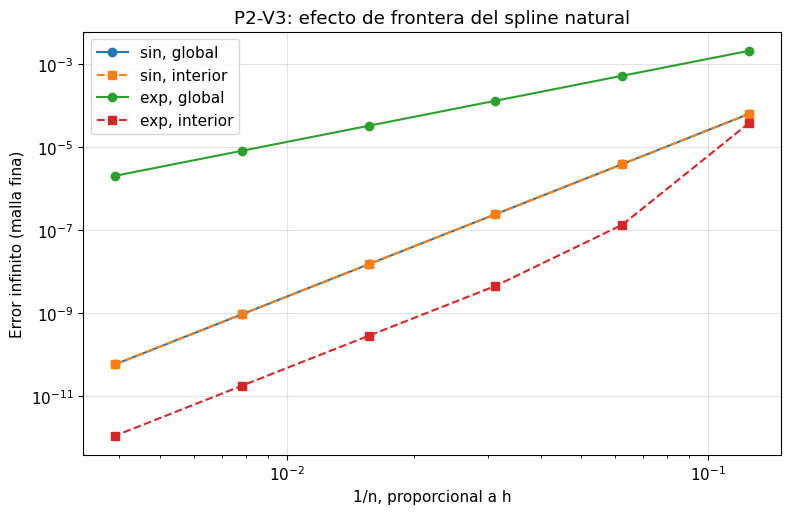

In [18]:

def thomas(a, b, c, d):
    """Resuelve Ax=d con LU tridiagonal y cuenta 8n-7 operaciones."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)
    d = np.asarray(d, dtype=float)
    n = len(b)
    if n == 0 or any(len(v) != n for v in (a, c, d)):
        raise ValueError("Los cuatro vectores deben tener longitud n >= 1")
    gamma = np.zeros(n)
    y = np.zeros(n)
    cuenta = 0
    pivote = b[0]
    if abs(pivote) <= 1e-14:
        raise ZeroDivisionError("Thomas: pivote cero en la primera fila")
    if n > 1:
        gamma[0] = c[0] / pivote
        cuenta += 1
    y[0] = d[0] / pivote
    cuenta += 1
    for i in range(1, n):
        pivote = b[i] - a[i] * gamma[i - 1]
        cuenta += 2
        if abs(pivote) <= 1e-14:
            raise ZeroDivisionError(f"Thomas: pivote cero en la fila {i + 1}")
        if i < n - 1:
            gamma[i] = c[i] / pivote
            cuenta += 1
        y[i] = (d[i] - a[i] * y[i - 1]) / pivote
        cuenta += 3
    sol = y.copy()
    for i in range(n - 2, -1, -1):
        sol[i] = y[i] - gamma[i] * sol[i + 1]
        cuenta += 2
    return sol, cuenta


def spline_natural(x, y):
    """Halla M_i=S''(x_i) resolviendo el sistema tridiagonal."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    h = np.diff(x)
    if len(x) < 2 or len(x) != len(y) or np.any(h <= 0):
        raise ValueError("Se requieren nodos estrictamente crecientes")
    M = np.zeros(len(x))
    k = len(x) - 2
    if k == 0:
        return M
    delta = np.diff(y) / h
    a = np.zeros(k)
    b = 2 * (h[:-1] + h[1:])
    c = np.zeros(k)
    if k > 1:
        a[1:] = h[1:-1]
        c[:-1] = h[1:-1]
    d = 6 * np.diff(delta)
    M[1:-1], _ = thomas(a, b, c, d)
    return M


def evaluar_spline(x, y, M, t):
    """Evalúa el spline natural cúbico en el subintervalo correspondiente."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    M = np.asarray(M, dtype=float)
    j = np.clip(np.searchsorted(x, t, side='right') - 1, 0, len(x) - 2)
    h = x[j + 1] - x[j]
    izq = x[j + 1] - t
    der = t - x[j]
    val = (M[j] * izq ** 3 / (6 * h)
           + M[j + 1] * der ** 3 / (6 * h)
           + (y[j] / h - M[j] * h / 6) * izq
           + (y[j + 1] / h - M[j + 1] * h / 6) * der)
    return float(val) if val.ndim == 0 else val


def hermite(x, fx, dfx, t):
    """Interpolación global de Hermite usando bases de Lagrange."""
    x = np.asarray(x, dtype=float)
    fx = np.asarray(fx, dtype=float)
    dfx = np.asarray(dfx, dtype=float)
    t = np.asarray(t, dtype=float)
    val = np.zeros_like(t, dtype=float)
    for i in range(len(x)):
        li = np.ones_like(t, dtype=float)
        deriv_li = 0.0
        for j in range(len(x)):
            if i != j:
                li *= (t - x[j]) / (x[i] - x[j])
                deriv_li += 1 / (x[i] - x[j])
        val += ((1 - 2 * (t - x[i]) * deriv_li) * fx[i]
                + (t - x[i]) * dfx[i]) * li ** 2
    return float(val) if val.ndim == 0 else val


def runge(x):
    """Función de Runge."""
    return 1 / (1 + 25 * np.asarray(x) ** 2)


def drunge(x):
    """Primera derivada exacta de Runge."""
    x = np.asarray(x)
    return -50 * x / (1 + 25 * x ** 2) ** 2


def d2runge(x):
    """Segunda derivada exacta de Runge."""
    x = np.asarray(x)
    return (-50 + 3750 * x ** 2) / (1 + 25 * x ** 2) ** 3


print("V1: coste del algoritmo de Thomas")
rng = np.random.default_rng(2026)
print(f"{'N':>8} {'residuo relativo':>19} {'ops':>12} {'8N-7':>12} {'segundos':>11}")
tamanos = [10, 100, 1000, 10000, 100000]
tiempos = []
for N in tamanos:
    h = .75 + .5 * rng.random(N + 1)
    x = np.concatenate(([0.0], np.cumsum(h)))
    yy = np.sin(x / 10)
    diag = 2 * (h[:-1] + h[1:])
    sub = np.zeros(N)
    sup = np.zeros(N)
    sub[1:] = h[1:-1]
    sup[:-1] = h[1:-1]
    dd = 6 * np.diff(np.diff(yy) / h)
    inicio = time.perf_counter()
    m, ops = thomas(sub, diag, sup, dd)
    tseg = time.perf_counter() - inicio
    Ax = diag * m
    Ax[1:] += sub[1:] * m[:-1]
    Ax[:-1] += sup[:-1] * m[1:]
    residuo = np.max(np.abs(Ax - dd)) / max(np.max(np.abs(dd)), U)
    tiempos.append(tseg)
    print(f"{N:8d} {residuo:19.7e} {ops:12d} {8*N-7:12d} {tseg:11.5f}")
plt.figure()
plt.loglog(tamanos, tiempos, 'o-', label='Tiempo de Thomas')
plt.xlabel('Tamaño N del sistema')
plt.ylabel('Tiempo de ejecución (s)')
plt.title('P2-V1: costo O(N) para sistemas tridiagonales')
plt.legend()
plt.show()
try:
    thomas(np.array([0, 1, 1]), np.array([1, 1, 1]),
           np.array([1, 1, 0]), np.array([1, 2, 3]))
except ZeroDivisionError as exc:
    print('Matriz no diagonalmente dominante, det(A)=-1:', exc)
    print('Aunque A es invertible, Thomas sin pivoteo falla porque el segundo pivote es 0.')

print("V2: interpolantes sobre Runge")
malla1001 = np.linspace(-1, 1, 1001)
malla2001 = np.linspace(-1, 1, 2001)
print('nodos  malla   ||f-L||inf      ||f-H||inf      ||f-S||inf')
for n_nodos in (6, 12, 24):
    xx = np.linspace(-1, 1, n_nodos)
    yy = runge(xx)
    dy = drunge(xx)
    Mi = spline_natural(xx, yy)
    for malla in (malla1001, malla2001):
        errs = [np.max(np.abs(runge(malla) - metodo(malla))) for metodo in (
            lambda z: lagrange(xx, yy, z),
            lambda z: hermite(xx, yy, dy, z),
            lambda z: evaluar_spline(xx, yy, Mi, z))]
        print(f'{n_nodos:5d} {len(malla):6d} ' + ' '.join(f'{e:15.5e}' for e in errs))
    if n_nodos == 12:
        plt.figure()
        plt.plot(malla2001, runge(malla2001), 'k', label='f: Runge')
        plt.plot(malla2001, lagrange(xx, yy, malla2001), label='Lagrange')
        plt.plot(malla2001, hermite(xx, yy, dy, malla2001), label='Hermite')
        plt.plot(malla2001, evaluar_spline(xx, yy, Mi, malla2001), label='Spline natural')
        plt.plot(xx, yy, 'ko', ms=3, label='12 nodos')
        plt.xlabel('x')
        plt.ylabel('Valor interpolado')
        plt.title('P2-V2: interpolantes de Runge con 12 nodos')
        plt.legend()
        plt.show()

print("V3: error de spline natural en interior y extremos")
resultado_spline = {}
for nombre, fun, f2, aa, bb in (
    ('sin', np.sin, lambda z: -np.sin(z), 0.0, np.pi),
    ('exp', np.exp, np.exp, 0.0, 1.0)):
    fil = []
    for k in range(3, 9):
        n = 2 ** k
        xx = np.linspace(aa, bb, n + 1)
        Mi = spline_natural(xx, fun(xx))
        mallaglobal = np.linspace(aa, bb, 4001)
        mallainterior = np.linspace(3/8, 5/8, 2001) if nombre == 'exp' else np.linspace(3*np.pi/8, 5*np.pi/8, 2001)
        eg = np.max(np.abs(fun(mallaglobal)-evaluar_spline(xx, fun(xx), Mi, mallaglobal)))
        ei = np.max(np.abs(fun(mallainterior)-evaluar_spline(xx, fun(xx), Mi, mallainterior)))
        fil.append((n, eg, ei, Mi[0], f2(xx[0]), Mi[1], f2(xx[1])))
    resultado_spline[nombre] = fil
    print('Función:', nombre)
    print('   n      error global      error interior       M0         f"(a)')
    for n, eg, ei, M0, f20, M1, f21 in fil:
        print(f'{n:5d}   {eg:14.6e}   {ei:14.6e} {M0:10.4g} {f20:10.4g}')
    for campo, etiqueta in ((1, 'global'), (2, 'interior')):
        ords = [np.log2(fil[i][campo] / fil[i+1][campo]) for i in range(len(fil)-1)]
        print(f'Órdenes {etiqueta} para mallas consecutivas:', np.round(ords, 3))
plt.figure()
for nombre, fil in resultado_spline.items():
    plt.loglog([1/r[0] for r in fil], [r[1] for r in fil], 'o-', label=f'{nombre}, global')
    plt.loglog([1/r[0] for r in fil], [r[2] for r in fil], 's--', label=f'{nombre}, interior')
plt.xlabel('1/n, proporcional a h')
plt.ylabel('Error infinito (malla fina)')
plt.title('P2-V3: efecto de frontera del spline natural')
plt.legend()
plt.show()


### **Conclusiones del Problema 2**

**V1:** Para tamaños $N=10,100,10^3,10^4,10^5$, el programa contabilizó exactamente $8N-7$ operaciones y produjo residuos relativos del orden de $10^{-16}$. El conteo procede de sumar las divisiones de las superdiagonales, las actualizaciones de pivotes y las dos sustituciones triangulares, no de ajustar una curva a los tiempos. Los tiempos observados aumentaron aproximadamente en proporción a $N$, como lo predice el costo $O(N)$.

Para la matriz

$$A=\begin{pmatrix}1&1&0\\1&1&1\\0&1&1\end{pmatrix},$$

se tiene $\det(A)=-1$, pero el primer pivote es $\beta_0=1$, después $\gamma_0=1$ y el siguiente pivote se anula: $\beta_1=1-1\cdot1=0$. En consecuencia, ser invertible no es suficiente para aplicar Thomas sin pivoteo. No hay contradicción con T2 porque esta matriz no satisface la dominancia diagonal estricta.

**V2:** Para $f(x)=1/(1+25x^2)$ y 24 nodos uniformes, las normas máximas aproximadas fueron

$$\|f-L\|_\infty\approx3.640\times10^1,\qquad
\|f-H\|_\infty\approx3.307\times10^4,\qquad
\|f-S\|_\infty\approx5.372\times10^{-3}.$$

La causa es estructural: $L$ y $H$ son polinomios globales, cuyos grados crecen con el número de condiciones, el spline conserva grado 3 en cada subintervalo y acopla los tramos mediante continuidad hasta la segunda derivada (AN-3.5-Hermite-Splines, pp. 1–3 y 15–20). El fenómeno de Runge puede intensificarse en el interpolante de Hermite con muchos nodos uniformes, aunque este utilice también información de pendientes. Las normas medidas con 1001 y con 2001 puntos son máximos de mallas, y por tanto pueden diferir del supremo continuo o entre sí.

**V3:** Para $f(x)=\sin x$ sobre $[0,\pi]$ se cumplen $f''(0)=f''(\pi)=0$: las condiciones del spline natural son compatibles con la función, y se observó orden global cercano a 4. Para $f(x)=e^x$ sobre $[0,1]$, en cambio, $f''(0)=1$ y $f''(1)=e$, mientras el spline impone $M_0=M_n=0$. La curvatura se modifica cerca de ambos extremos. El error global cae aproximadamente como $O(h^2)$, aunque en el intervalo interior fijo $[3/8,5/8]$ se recupera el comportamiento de orden cercano a 4. La diferencia demuestra que el error de frontera puede dominar la norma global incluso cuando la interpolación interior es muy buena.

En conclusión, Thomas es eficiente porque aprovecha la estructura tridiagonal del sistema, pero necesita pivotes no nulos. El spline natural evita las oscilaciones de un polinomio global de grado alto en las pruebas con Runge. Su precisión cerca de los extremos depende de si los datos reales son compatibles con las condiciones naturales.

---
## Problema 3 — Derivación numérica: fórmulas por interpolación, error total y Richardson
*Temario: §4.1 y §4.2 (enlace con §3.1 y §3.3).*

**T1 (teoría).** Sean $x_0,\dots,x_n$ nodos distintos en $I=[a,b]$, $f\in C^{n+1}(I)$ y $L_n$ su polinomio de interpolación. Pruebe que para cada nodo $x_j$ existe $\xi_j\in I$ tal que
$$f'(x_j)=L_n'(x_j)+\frac{f^{(n+1)}(\xi_j)}{(n+1)!}\,\Psi_n'(x_j),\qquad \Psi_n'(x_j)=\prod_{i\ne j}(x_j-x_i).$$
*Sugerencia:* escriba $\dfrac{f(x)-L_n(x)}{x-x_j}$ con la Proposición 4 (AN-LN-3-3, p. 13), haga $x\to x_j$ y use el Teorema 4 (p. 14) y el teorema del valor intermedio; no derive $\xi(x)$. Aplique el resultado a los nodos $x_0,x_0+h,x_0+2h$ para obtener la fórmula de tres puntos en el extremo (AN-4.1, Ejemplo 4.3, p. 10) con su término de error explícito.

**T2 (teoría).** A partir de la expansión (4.1) de AN-4.1 (p. 18), demuestre la ecuación (4.3) (p. 19):
$$f'(x)=R(h)+\frac{h^4}{480}f^{(5)}(x)+O(h^6),\qquad R(h)=N\!\left(\tfrac h2\right)+\frac{N(h/2)-N(h)}{2^2-1},$$
y pruebe que la recurrencia de §4.3.2 (p. 24), $N_{i+1}(h)=N_i(h/2)+\dfrac{N_i(h/2)-N_i(h)}{2^{k_i}-1}$ con $k_i=2i+2$, produce aproximaciones de orden $h^2,h^4,h^6,h^8,\dots$ ¿Qué regularidad de $f$ requiere el orden $h^{8}$?

**Implementación.** `dif_adelante(f, x0, h)`, `dif_central(f, x0, h)`, `dif_3p_extremo(f, x0, h)`, `dif_5p_central(f, x0, h)`, `segunda_central(f, x0, h)` (la usará el Problema 4) y `richardson(N, h, niveles)`, que construye la tabla triangular de Richardson para una aproximación $N(h)$ con expansión en potencias pares de $h$.

**V1 (validación).** Para $f(x)=xe^x$ y $x_0=2$, con $h=2^{-k}$, $k=1,\dots,40$: grafique en escala log–log el error de las cuatro fórmulas de primera derivada; estime las pendientes en el régimen de truncamiento; localice el $h$ óptimo empírico de la fórmula central y compárelo con $h^*=\sqrt[3]{3\epsilon/M}$ del modelo de error total de AN-4.1 (p. 14), con $\epsilon=u\,|f(x_0)|$ y $M=|f'''(x_0)|$. Compare también el error mínimo observado con $e(h^*)$.

**V2 (validación).** Reproduzca el Ejemplo 4.5 de AN-4.1 (p. 20): $N(0{,}2)$, $N(0{,}1)$ y $R(0{,}2)$. Verifique numéricamente que $\bigl(f'(2)-R(h)\bigr)/h^4\to f^{(5)}(2)/480$ (calcule $f^{(5)}$). Construya la tabla de Richardson de 4 niveles con $h_0=0{,}8,0{,}4,\dots$, estime los órdenes de cada columna e indique en qué nivel el redondeo detiene la mejora.


#### **T1.**

Sean $x_0,\ldots,x_n$ nodos distintos de $[a,b]$, $f\in C^{n+1}[a,b]$ y $L_n$ su interpolante. Escribimos $\Psi_n(x)=\prod_{i=0}^n(x-x_i)$. La expresión del error de interpolación mediante diferencias divididas se encuentra en AN-3.3, Proposición 4, p. 26.

Como $f(x_j)=L_n(x_j)$, para $x\ne x_j$ podemos escribir

$$\frac{f(x)-L_n(x)}{x-x_j}=f[x_0,\ldots,x_n,x]\prod_{i\ne j}(x-x_i).$$

No estamos derivando la forma $f^{(n+1)}(\xi_x)$, porque el punto $\xi_x$ depende de $x$ de manera desconocida.

Por la definición de derivada aplicada a la función $f-L_n$, tenemos que

$$\lim_{x\to x_j}\frac{f(x)-L_n(x)}{x-x_j}=f'(x_j)-L_n'(x_j).$$

Los factores del producto convergen a $\prod_{i\ne j}(x_j-x_i)$. La diferencia dividida admite el límite $f[x_0,\ldots,x_n,x_j]$, para una función suficientemente suave, ese valor está entre el mínimo y el máximo de $f^{(n+1)}/(n+1)!$.

El teorema de valor medio para diferencias divididas (AN-3.3, Teorema 4, p. 27) y la continuidad de $f^{(n+1)}$ garantizan algún $\xi_j\in[a,b]$ tal que

$$f[x_0,\ldots,x_n,x_j]=\frac{f^{(n+1)}(\xi_j)}{(n+1)!}.$$

Como $\Psi_n$ tiene un factor $(x-x_j)$ que se anula en $x_j$, al derivar el producto únicamente sobrevive la derivada de ese factor:

$$\Psi_n'(x_j)=\prod_{i\ne j}(x_j-x_i).$$

Luego,

$$\boxed{f'(x_j)=L_n'(x_j)+\frac{f^{(n+1)}(\xi_j)}{(n+1)!}\Psi_n'(x_j).}$$

Elegimos $x_0,x_0+h,x_0+2h$, con $h>0$. En la base de Lagrange, los tres polinomios cardinales son

$$\ell_0(x)=\frac{(x-x_0-h)(x-x_0-2h)}{2h^2},$$

$$\ell_1(x)=-\frac{(x-x_0)(x-x_0-2h)}{h^2},\qquad
\ell_2(x)=\frac{(x-x_0)(x-x_0-h)}{2h^2}.$$

Sus derivadas en $x_0$ valen, respectivamente,

$$\ell'_0(x_0)=-\frac{3}{2h},\quad\ell'_1(x_0)=\frac2h,\quad\ell'_2(x_0)=-\frac1{2h}.$$

Por tanto,

$$L'_2(x_0)=\frac{-3f(x_0)+4f(x_0+h)-f(x_0+2h)}{2h}.$$

El producto nodal satisface $\Psi_2'(x_0)=(-h)(-2h)=2h^2$. Aplicando la fórmula demostrada con $n=2$,

$$\boxed{f'(x_0)=\frac{-3f(x_0)+4f(x_0+h)-f(x_0+2h)}{2h}+\frac{h^2}{3}f'''(\xi),\quad \xi\in[x_0,x_0+2h].}$$

Es una regla de tres puntos con error $O(h^2)$, esta corresponde al desarrollo de diferencias por interpolación de AN-4.1, pp. 9–10.

#### **T2.**

Tomemos la diferencia central $N(h)=[f(x+h)-f(x-h)]/(2h)$ y supongamos derivadas suficientes para desarrollar Taylor hasta el orden requerido (AN-4.1, pp. 17–19).

Escribimos

$$\begin{aligned}
f(x+h)={}&f(x)+hf'(x)+\frac{h^2}{2!}f''(x)+\frac{h^3}{3!}f'''(x)+\frac{h^4}{4!}f^{(4)}(x)+\frac{h^5}{5!}f^{(5)}(x)+\cdots,\\
f(x-h)={}&f(x)-hf'(x)+\frac{h^2}{2!}f''(x)-\frac{h^3}{3!}f'''(x)+\frac{h^4}{4!}f^{(4)}(x)-\frac{h^5}{5!}f^{(5)}(x)+\cdots.
\end{aligned}$$

Al restar desaparecen los términos pares. Al dividir por $2h$:

$$\boxed{N(h)=f'(x)+\frac{h^2}{6}f'''(x)+\frac{h^4}{120}f^{(5)}(x)+\frac{h^6}{5040}f^{(7)}(x)+O(h^8).}$$

Resulta

$$N(h/2)=f'(x)+\frac{h^2}{24}f'''(x)+\frac{h^4}{1920}f^{(5)}(x)+\frac{h^6}{322560}f^{(7)}(x)+O(h^8).$$

Multiplicamos esta segunda expresión por cuatro y le restamos $N(h)$:

$$4N(h/2)-N(h)=3f'(x)+\left(\frac4{24}-\frac16\right)h^2f'''(x)+\left(\frac4{1920}-\frac1{120}\right)h^4f^{(5)}(x)+O(h^6).$$

El coeficiente de $h^2$ es $0$, y el de $h^4$ es $-1/160$. Dividiendo toda la expresión entre $3$, obtenemos

$$R(h)=\frac{4N(h/2)-N(h)}3=f'(x)-\frac{h^4}{480}f^{(5)}(x)+O(h^6).$$

Despejando, conseguimos

$$\boxed{f'(x)=R(h)+\frac{h^4}{480}f^{(5)}(x)+O(h^6).}$$

Supongamos que la columna $i$ tiene expansión

$$N_i(h)=D+C_i h^{2i+2}+O(h^{2i+4}),\qquad D=f'(x).$$

Se define la siguiente extrapolación como

$$\boxed{N_{i+1}(h)=N_i(h/2)+\frac{N_i(h/2)-N_i(h)}{2^{2i+2}-1}.}$$

El coeficiente que acompaña a $h^{2i+2}$ es

$$\frac{C_i}{2^{2i+2}}+\frac{C_i/2^{2i+2}-C_i}{2^{2i+2}-1}=0.$$

Por lo tanto, desaparece el primer término de error y queda $N_{i+1}(h)=D+O(h^{2i+4})$. Desde $i=0$ se obtienen sucesivamente

$$\boxed{O(h^2),\ O(h^4),\ O(h^6),\ O(h^8),\ldots.}$$

Esta es la recurrencia de extrapolación de AN-4.1, pp. 20–24. Para garantizar hasta $O(h^8)$ por la serie de Taylor de la diferencia central, es suficiente $f\in C^9$ en una vecindad de $x$. Para asegurar más columnas hacen falta derivadas adicionales.

El error de truncamiento de la diferencia central decrece como $h^2$, pero el redondeo en la resta $f(x+h)-f(x-h)$ puede crecer al dividir por $h$. Un modelo habitual del error total tiene la forma

$$E(h)\lesssim Ah^2+\frac{B\,u}{h},$$

con $u=2^{-53}$, al minimizarlo da un paso óptimo positivo. Por eso los órdenes predichos solo se estiman en el intervalo de pasos donde todavía predomina el truncamiento y no la pérdida de cifras significativas.

V1: derivación de f(x)=x exp(x) en x=2
Adelante O(h): pendiente truncamiento estimada=1.0047; error mínimo=8.2038e-08
Central O(h²): pendiente truncamiento estimada=2.0000; error mínimo=8.1620e-11
Extremo 3p O(h²): pendiente truncamiento estimada=2.0102; error mínimo=8.1620e-11
Central 5p O(h⁴): pendiente truncamiento estimada=4.0002; error mínimo=8.4199e-13


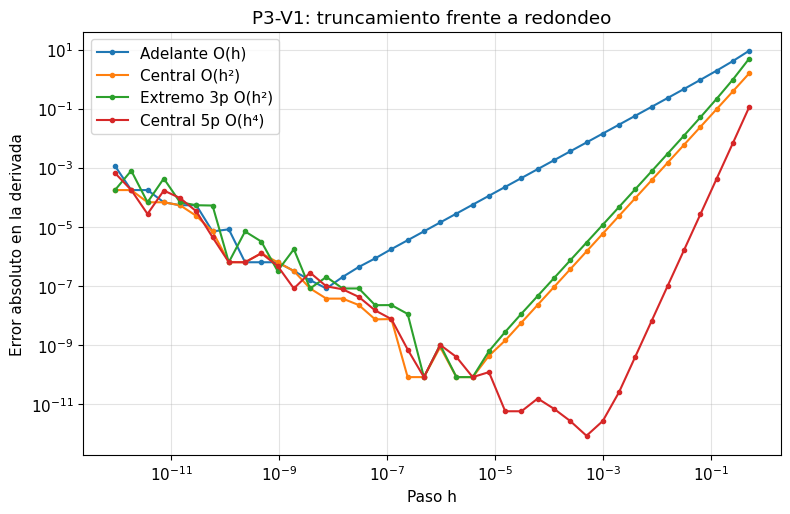

Central: h óptimo empírico: 3.814697265625e-06 ; error mínimo real: 8.162004405676271e-11
Modelo h* = (3 ε/M)^(1/3): 5.107368088395462e-06 ; e(h*) estimado: 4.818626777607276e-10
Razón h_empírico/h*: 0.7469007910928603
V2: Richardson
N(0.2)=22.414160657029, N(0.1)=22.228786880307, R(0.2)=22.166995621400
f^(5)(2)/480 = 0.10775706810940532
    h     (f'(2)-R(h))/h^4
0.40000        0.108418690010
0.20000        0.107922120016
0.10000        0.107798309408
0.05000        0.107767389181
0.02500        0.107759015009
0.01250        0.107745145215
Tabla de Richardson 4 niveles (triangular):
h = 0.80000: 26.288044157367
h = 0.40000: 23.163464293135  22.121937671724
h = 0.20000: 22.414160657029  22.164392778328  22.167223118768
h = 0.10000: 22.228786880307  22.166995621400  22.167169144271  22.167168287533
Columna 0: órdenes antes de redondeo: [2. 2. 2. 2.] mejor error: 3.758270615605852e-06
Columna 1: órdenes antes de redondeo: [4.   3.99 3.86 2.13] mejor error: 2.6076918402395677e-12
Columna 

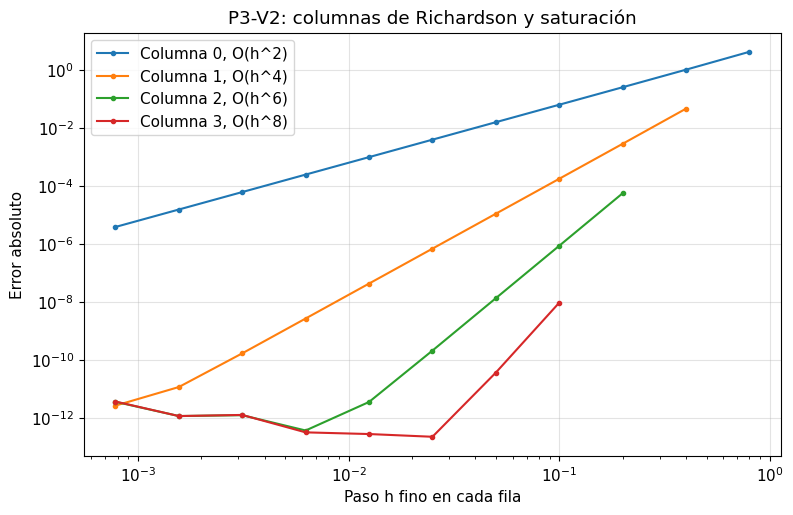

In [19]:

def dif_adelante(f, x0, h):
    """Primera derivada hacia adelante, error O(h)."""
    return (f(x0 + h) - f(x0)) / h


def dif_central(f, x0, h):
    """Primera derivada central, error O(h^2)."""
    return (f(x0 + h) - f(x0 - h)) / (2 * h)


def dif_3p_extremo(f, x0, h):
    """Primera derivada de tres nodos hacia adelante, error O(h^2)."""
    return (-3*f(x0) + 4*f(x0+h) - f(x0+2*h)) / (2*h)


def dif_5p_central(f, x0, h):
    """Primera derivada central de cinco nodos, error O(h^4)."""
    return (f(x0-2*h)-8*f(x0-h)+8*f(x0+h)-f(x0+2*h))/(12*h)


def segunda_central(f, x0, h):
    """Segunda derivada por tres nodos, error O(h^2)."""
    return (f(x0+h)-2*f(x0)+f(x0-h))/h**2


def richardson(N, h, niveles):
    """Tabla triangular de extrapolación: cancela h^2, h^4, etc."""
    T = np.full((niveles, niveles), np.nan)
    for i in range(niveles):
        T[i, 0] = N(h / (2 ** i))
        for j in range(1, i + 1):
            T[i, j] = T[i, j-1] + (T[i, j-1]-T[i-1, j-1])/(4**j-1)
    return T


print("V1: derivación de f(x)=x exp(x) en x=2")
f3 = lambda x: x*np.exp(x)
x03 = 2.0
real3 = 3*np.exp(2)
hs3 = 2.0 ** (-np.arange(1, 41))
metodos3 = {
    'Adelante O(h)': dif_adelante,
    'Central O(h²)': dif_central,
    'Extremo 3p O(h²)': dif_3p_extremo,
    'Central 5p O(h⁴)': dif_5p_central,
}
errores3 = {}
plt.figure()
for nombre, metodo in metodos3.items():
    err = np.array([abs(metodo(f3, x03, h)-real3) for h in hs3])
    errores3[nombre] = err
    muestra = np.median([np.log2(err[i] / err[i+1]) for i in range(3, 8)
                        if err[i] > 0 and err[i+1] > 0])
    print(f'{nombre}: pendiente truncamiento estimada={muestra:.4f}; error mínimo={np.min(err):.4e}')
    plt.loglog(hs3, np.maximum(err, U), 'o-', ms=3, label=nombre)
plt.xlabel('Paso h')
plt.ylabel('Error absoluto en la derivada')
plt.title('P3-V1: truncamiento frente a redondeo')
plt.legend()
plt.show()
err_central = errores3['Central O(h²)']
pos_opt = int(np.argmin(err_central))
epsilon3 = U * abs(f3(x03))
M3 = 5*np.exp(2)
h_pred = (3*epsilon3/M3)**(1/3)
err_pred = M3*h_pred**2/6 + epsilon3/h_pred
print('Central: h óptimo empírico:', hs3[pos_opt],
      '; error mínimo real:', err_central[pos_opt])
print('Modelo h* = (3 ε/M)^(1/3):', h_pred, '; e(h*) estimado:', err_pred)
print('Razón h_empírico/h*:', hs3[pos_opt] / h_pred)

print("V2: Richardson")
N3 = lambda h: dif_central(f3, x03, h)
T2 = richardson(N3, 0.2, 2)
print(f'N(0.2)={N3(.2):.12f}, N(0.1)={N3(.1):.12f}, R(0.2)={T2[1,1]:.12f}')
fifth = 7*np.exp(2)
print('f^(5)(2)/480 =', fifth/480)
print('    h     (f\'(2)-R(h))/h^4')
for h in [.4, .2, .1, .05, .025, .0125]:
    R = richardson(N3, h, 2)[1, 1]
    print(f'{h:7.5f} {((real3-R)/h**4):21.12f}')
T4 = richardson(N3, 0.8, 4)
print('Tabla de Richardson 4 niveles (triangular):')
for i in range(4):
    print(f'h = {0.8/2**i:.5f}:',
          '  '.join(f'{T4[i,j]:.12f}' for j in range(i+1)))
Text = richardson(N3, .8, 11)
plt.figure()
for j in range(4):
    filas = np.arange(j, len(Text))
    hs = .8 / 2.0**filas
    err = np.abs(Text[filas, j]-real3)
    plt.loglog(hs, np.maximum(err, U), 'o-', ms=3, label=f'Columna {j}, O(h^{2*j+2})')
    ords = [np.log2(err[k]/err[k+1]) for k in range(len(err)-1)
            if err[k+1] > 1e-12 and err[k] > err[k+1]]
    print(f'Columna {j}: órdenes antes de redondeo:', np.round(ords[-4:], 2),
          'mejor error:', np.min(err))
plt.xlabel('Paso h fino en cada fila')
plt.ylabel('Error absoluto')
plt.title('P3-V2: columnas de Richardson y saturación')
plt.legend()
plt.show()

### **Conclusiones del Problema 3**

**V1:** Las pendientes medidas en la región donde domina el truncamiento fueron aproximadamente $1.00$ para la diferencia hacia adelante, $2.00$ para la central, $2.01$ para la fórmula de tres puntos en el extremo y $4.00$ para la central de cinco puntos. Concuerdan con las potencias $h,h^2,h^2,h^4$ que se obtienen al cancelar los términos de Taylor. Para pasos demasiado pequeños, las restas entre valores casi iguales pierden precisión, luego el error deja de decrecer.

La fórmula central tuvo un mínimo observado cercano a $8.16\times10^{-11}$ cuando $h=2^{-18}\approx3.81\times10^{-6}$. Con el modelo de error total, tomamos $\varepsilon=u|f(2)|$ y $M=|f'''(2)|=5e^2$, así el paso de equilibrio es

$$h^*=\left(\frac{3\varepsilon}{M}\right)^{1/3}\approx5.11\times10^{-6},$$

con cota-modelo del error $e(h^*)\approx4.82\times10^{-10}$. No debe exigirse coincidencia exacta entre el mínimo observado y el modelo, pues el modelo da una estimación conservadora de la contribución del redondeo, mientras que una ejecución concreta puede tener cancelaciones favorables.

**V2:** La implementación obtuvo

$$N(0.2)=22.4141606570,\qquad N(0.1)=22.2287868803,\qquad R(0.2)=22.1669956214.$$

El valor de referencia es $3e^2\approx22.1671682968$. La extrapolación $R(h)=[4N(h/2)-N(h)]/3$ elimina el término $h^2$ de la diferencia central y deja

$$f'(2)-R(h)=\frac{h^4}{480}f^{(5)}(2)+O(h^6).$$

Por ello, antes de llegar al redondeo,

$$\frac{f'(2)-R(h)}{h^4}\longrightarrow\frac{7e^2}{480}\approx0.1077570681.$$

La tabla de Richardson contiene columnas de órdenes teóricos 2, 4, 6 y 8. El método acelera la reducción del error de truncamiento, pero combinar aproximaciones próximas no elimina el límite físico de la precisión de máquina.

En conclusión, reducir $h$ mejora el error de truncamiento solo hasta cierto punto. Por debajo de ese valor prevalece el redondeo. Richardson puede aumentar considerablemente el orden, siempre que la función tenga suficiente regularidad y los cálculos permanezcan fuera del régimen dominado por el redondeo.

---
## Problema 4 — Integración compuesta y Romberg: hipótesis, órdenes y costo
*Temario: §4.3, §4.4 y §4.5 (enlace con §4.2 y §3.5).*

Sea $T(h)$ la regla del trapecio compuesta y $S(h)$ la de Simpson compuesta con paso $h=(b-a)/n$.

**T1 (teoría).** Pruebe que la regla de Simpson tiene grado de precisión 3 (AN-4.2, Def. 5.1, p. 1, y Teor. 5.2, p. 14). Deduzca su término de error $-\frac{h^5}{90}f^{(4)}(\eta)$ integrando el error del polinomio de Hermite que interpola $f(x_0),f(x_1),f'(x_1),f(x_2)$ (AN-LN-3-4, Teorema 1), y obtenga el error de la regla compuesta $-\frac{(b-a)h^4}{180}f^{(4)}(\eta)$ con el argumento del valor intermedio de AN-4.2, §5.2 (p. 9).

**T2 (teoría).** Pruebe que $\dfrac{4T(h)-T(2h)}{3}=S(h)$ (AN-4.2, §5.6, p. 21). Suponiendo la expansión de Euler–Maclaurin $T(h)=I+c_1h^2+c_2h^4+\cdots+c_mh^{2m}+O(h^{2m+2})$, con $c_k=\frac{B_{2k}}{(2k)!}\bigl(f^{(2k-1)}(b)-f^{(2k-1)}(a)\bigr)$, válida si $f\in C^{2m+2}[a,b]$, pruebe que la columna $k$ de Romberg tiene error $O(h^{2k+2})$ ($k=0,1,\dots$). Prediga qué ocurre (a) si $f\notin C^1[a,b]$ y (b) si $f$ es suave y periódica de periodo $b-a$.

**Implementación.** `trapecio_compuesto(f, a, b, n)`, `simpson_compuesto(f, a, b, n)` ($n$ par) y `romberg(f, a, b, m)`, que construye la tabla de $m$ filas reutilizando las evaluaciones: $T(h/2)=\tfrac12T(h)+\tfrac h2\sum f(\text{puntos medios})$. Use `ContadorEvaluaciones` para medir el costo.

**V1 (validación).** Para $\int_0^\pi\sin x\,dx=2$ reproduzca la tabla del ejemplo de AN-4.1 (pp. 22–23: 1,570796; 1,896119; 1,974232; 2,004560; 2,000270; 1,999984) y estime los órdenes de las columnas de Romberg. Para $\int_0^1e^x\,dx$ grafique error frente a número de evaluaciones para trapecio, Simpson y Romberg.

**V2 (validación).** Repita el análisis con (a) $\int_0^1\sqrt{x}\,dx=2/3$ y (b) $\int_0^{2\pi}e^{\cos x}dx=2\pi I_0(1)=$ 7,954926521013 ($I_0$: función de Bessel modificada; puede calcularse con la serie $I_0(1)=\sum_{k\ge0}\frac{1}{4^k(k!)^2}$). Contraste con las predicciones de T2.

**V3 (validación, integra el Problema 2).** Para la función de Runge en $[-1,1]$ con $n=6,12,24$ subintervalos uniformes:
1. Deduzca $\int_{x_i}^{x_{i+1}}S=\dfrac{h_i(y_i+y_{i+1})}{2}-\dfrac{h_i^3(M_i+M_{i+1})}{24}$ y compare $\int_{-1}^1S$ con Simpson compuesto sobre los mismos datos y con $\frac25\arctan5$. Verifique que Simpson aplicado a $S$ en cada subintervalo (con el punto medio) reproduce $\int S$ y explique por qué.
2. **Mínima energía** (AN-LN-3-4, Teorema 3, p. 13): calcule $\int_{-1}^1(S'')^2=\sum_i\frac{h_i}{3}(M_i^2+M_iM_{i+1}+M_{i+1}^2)$ y compárela con $\int(f'')^2$ y $\int(L_n'')^2$, calculadas con Simpson compuesto ($L_n''$ con `segunda_central`). Indique dónde intervienen $M_0=M_n=0$ en la demostración del teorema.

#### **T1.**

Sea $f\in C^4[m-h,m+h]$, con $h>0$. Tomamos los nodos $x_0=m-h$, $x_1=m$ y $x_2=m+h$. La regla de Simpson es (AN-4.2, pp. 9–14)

$$Q_S(f)=\frac h3\left[f(m-h)+4f(m)+f(m+h)\right].$$

Por linealidad basta comprobar $1,z,z^2,z^3$, donde $z=x-m$. En el intervalo simétrico $[-h,h]$ se tiene:

| Monomio | Integral exacta | Valor de Simpson |
|---|---:|---:|
| $1$ | $2h$ | $\frac h3(1+4+1)=2h$ |
| $z$ | $0$ | $\frac h3(-h+0+h)=0$ |
| $z^2$ | $\frac{2h^3}{3}$ | $\frac h3(h^2+0+h^2)=\frac{2h^3}{3}$ |
| $z^3$ | $0$ | $\frac h3(-h^3+0+h^3)=0$ |

Para $z^4$ la integral es $2h^5/5$, mientras que Simpson da $2h^5/3$, no coinciden. Por ende, el grado exacto de precisión algebraica es 3.

Sea $H_3$ el único polinomio cúbico que satisface

$$H_3(m-h)=f(m-h),\quad H_3(m)=f(m),\quad H'_3(m)=f'(m),\quad H_3(m+h)=f(m+h).$$

La unicidad de Hermite está desarrollada en AN-3.5-Hermite-Splines, Teorema 5.3, p. 9. Su resto tiene un nodo central repetido:

$$f(x)-H_3(x)=\frac{f^{(4)}(\xi_x)}{4!}(x-m+h)(x-m)^2(x-m-h).$$

Como Simpson es exacto para cualquier polinomio cúbico y $H_3$ comparte los tres valores de $f$ empleados por la regla, $Q_S(H_3)=Q_S(f)$ y así

$$I(f)-Q_S(f)=\int_{m-h}^{m+h}[f(x)-H_3(x)]\,dx.$$

Al hacer $z=x-m$, el peso es

$$w(z)=(z+h)z^2(z-h)=z^4-h^2z^2\le0\quad(-h\le z\le h).$$

El peso no cambia de signo. Aplicando el argumento de valor medio integral a una función continua $f^{(4)}$, existe $\eta\in[m-h,m+h]$ tal que

$$I(f)-Q_S(f)=\frac{f^{(4)}(\eta)}{24}\int_{-h}^h(z^4-h^2z^2)\,dz.$$

Calculamos las dos integrales elementales y su resultado es:

$$\int_{-h}^hz^4\,dz=\frac{2h^5}{5},\qquad h^2\int_{-h}^hz^2\,dz=\frac{2h^5}{3}.$$

Por ende,

$$\begin{aligned}I(f)-Q_S(f)&=\frac{f^{(4)}(\eta)}{24}\left(\frac{2h^5}{5}-\frac{2h^5}{3}\right)\\&=\boxed{-\frac{h^5}{90}f^{(4)}(\eta).}\end{aligned}$$

Supongamos $n$ subintervalos con $n$ par y paso $h=(b-a)/n$. Hay $n/2$ paneles de Simpson, cada uno de ancho $2h$. Sumando sus errores obtenemos,

$$I(f)-S(h)=-\frac{h^5}{90}\sum_{j=1}^{n/2}f^{(4)}(\eta_j).$$

Los valores $f^{(4)}(\eta_j)$ están entre el mínimo y el máximo de $f^{(4)}$ en $[a,b]$. Su promedio también está en ese rango. Por continuidad, existe $\eta\in[a,b]$ tal que el promedio es $f^{(4)}(\eta)$. Como hay $n/2$ términos, luego

$$\boxed{I(f)-S(h)=-\frac{nh^5}{180}f^{(4)}(\eta)=-\frac{(b-a)h^4}{180}f^{(4)}(\eta).}$$

El orden global es $O(h^4)$ siempre que la regularidad necesaria se cumpla.

#### **T2.**

Sean $n$ par y $x_j=a+jh$, $h=(b-a)/n$. Denotamos $f_j=f(x_j)$,

$$T(h)=h\left(\frac{f_0+f_n}{2}+\sum_{j=1}^{n-1}f_j\right),$$

$$T(2h)=2h\left(\frac{f_0+f_n}{2}+\sum_{j=1}^{n/2-1}f_{2j}\right).$$

Sustituyendo,

$$\begin{aligned}\frac{4T(h)-T(2h)}3
&=\frac h3\left[f_0+f_n+4\sum_{j\text{ impar}}f_j+2\sum_{\substack{2\le j\le n-2\\j\text{ par}}}f_j\right]\\
&=\boxed{S(h).}\end{aligned}$$

La primera igualdad resulta de que los nodos impares solo aparecen en $T(h)$, y los nodos pares interiores aparecen en ambos trapecios. La segunda es la fórmula de Simpson compuesta.

Supongamos que

$$T(h)=I+c_1h^2+c_2h^4+\cdots+c_mh^{2m}+O(h^{2m+2}),$$

con

$$c_j=\frac{B_{2j}}{(2j)!}\left[f^{(2j-1)}(b)-f^{(2j-1)}(a)\right],$$

si $f\in C^{2m+2}[a,b]$ y se cumplen las hipótesis de esta expansión.

En la primera columna se coloca $R_{i,0}=T(h_i)$, con $h_i=(b-a)/2^i$. Si una columna tiene error principal $Ch^{2k}$, al duplicar el paso ese error es $C(2h)^{2k}=4^kCh^{2k}$. La combinación

$$\boxed{R_{i,k}=R_{i,k-1}+\frac{R_{i,k-1}-R_{i-1,k-1}}{4^k-1}}$$

anula ese coeficiente. Partimos de la columna 0 con $O(h^2)$, tras una, dos y tres extrapolaciones se obtienen $O(h^4)$, $O(h^6)$ y $O(h^8)$, de manera respectiva. Por inducción la columna $k$ tiene error $O(h^{2k+2})$.

Si $f(x)=\sqrt{x}$ en $[0,1]$, entonces $f'(x)=1/(2\sqrt{x})$ diverge al aproximarnos a 0. Por tanto, $f\notin C^1[0,1]$ y no es válida la expansión anterior con derivadas regulares en los bordes ya que el error puede tener potencias fraccionarias y Romberg puede no ganar dos órdenes por columna. Si $f$ es suave y periódica, y sus derivadas coinciden en $a$ y $b$, entonces los coeficientes $c_j$ se anulan.

#### **V3.**

Usando $z=(x-x_i)/h_i$ y $dx=h_i\,dz$, los términos cúbicos se integran con $\int_0^1z^3\,dz=1/4$ y los lineales con $\int_0^1z\,dz=1/2$. Sustituyendo en la expresión de $S_i$ del Problema 2 y agrupando,

$$\boxed{\int_{x_i}^{x_{i+1}}S_i(x)\,dx=\frac{h_i}{2}(y_i+y_{i+1})-\frac{h_i^3}{24}(M_i+M_{i+1}).}$$

Simpson aplicado a cada tramo del spline, usando sus extremos y su punto medio, es exacto porque cada tramo es un polinomio de grado 3. Note que esto no es lo mismo que aplicar Simpson directamente a los datos de $f$ en paneles que cubren dos tramos.

Como $S_i''$ es lineal entre sus valores extremos,

$$S_i''(x_i+h_i z)=(1-z)M_i+zM_{i+1}.$$

Elevando al cuadrado e integrando,

$$\begin{aligned}\int_{x_i}^{x_{i+1}}(S_i'')^2\,dx&=h_i\int_0^1[(1-z)M_i+zM_{i+1}]^2\,dz\\&=\boxed{\frac{h_i}{3}(M_i^2+M_iM_{i+1}+M_{i+1}^2).}\end{aligned}$$

Sea $g\in C^2[a,b]$ cualquier otro interpolante de los mismos datos, y definamos $v=g-S$. Entonces $v(x_i)=0$ y

$$\int_a^b(g'')^2=\int_a^b(S'')^2+2\int_a^bS''v''+\int_a^b(v'')^2.$$

En cada tramo, $S_i$ es cúbico y por tanto $S_i''''=0$. Dos integraciones por partes dan

$$\int_{x_i}^{x_{i+1}}S_i''v''\,dx=\left[S_i''v'-S_i'''v\right]_{x_i}^{x_{i+1}}.$$

Al sumar los tramos los términos $S_i'''v$ en los nodos son cero porque $v(x_i)=0$, los términos interiores de $S_i''v'$ se cancelan porque $S''$ y $v'$ son continuas, los dos términos extremos desaparecen gracias a $S''(a)=S''(b)=0$. Por ello $\int_a^bS''v''=0$, y

$$\boxed{\int_a^b(g'')^2\,dx-\int_a^b(S'')^2\,dx=\int_a^b(v'')^2\,dx\ge0.}$$

V1: sin(x) en [0, pi]
Número de evaluaciones para 4 filas: 9 (esperado: 9)
Fila 0 : 0.000000000
Fila 1 : 1.570796327  2.094395102
Fila 2 : 1.896118898  2.004559755  1.998570732
Fila 3 : 1.974231602  2.000269170  1.999983131  2.000005550
Valores pedidos: R[1,0], R[2,0], R[3,0], R[2,1], R[3,1], R[3,2]
[np.float64(1.570796), np.float64(1.896119), np.float64(1.974232), np.float64(2.00456), np.float64(2.000269), np.float64(1.999983)]
Romberg seno, col 0 órdenes: [2.22  2.047 2.011 2.003 2.001]
Romberg seno, col 1 órdenes: [4.372 4.082 4.02  4.005 4.001]
Romberg seno, col 2 órdenes: [6.405 6.091 6.022 6.005 6.001]
Romberg seno, col 3 órdenes: [8.413 8.092 8.025   nan   nan]
P4-V1: costo de evaluaciones frente a error en exp(x)
   n  evaluaciones  err trapecio     err Simpson     err Romberg
   2            3    3.564926e-02    5.793234e-04    5.793234e-04
   4            5    8.940076e-03    3.701346e-05    8.594657e-07
   8            9    2.236764e-03    2.326241e-06    3.354852e-10
  16  

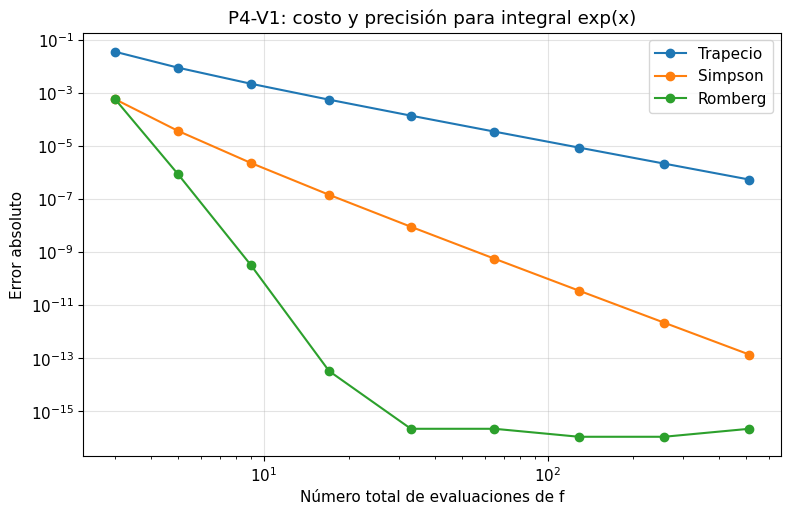

V2: falta de suavidad vs periodicidad
Integral periódica de referencia: 7.954926521012844
Caso sqrt(x)
n   errT   errS   errR
2 6.3113e-02 2.8595e-02 2.8595e-02
4 2.3384e-02 1.0140e-02 8.9101e-03
8 8.5364e-03 3.5874e-03 3.0591e-03
16 3.0855e-03 1.2685e-03 1.0738e-03
32 1.1077e-03 4.4848e-04 3.7897e-04
64 3.9586e-04 1.5856e-04 1.3393e-04
128 1.4101e-04 5.6061e-05 4.7345e-05
256 5.0118e-05 1.9820e-05 1.6738e-05
512 1.7785e-05 7.0076e-06 5.9179e-06
1024 6.3044e-06 2.4776e-06 2.0923e-06
2048 2.2331e-06 8.7595e-07 7.3973e-07
Órdenes a partir de las primeras cuatro mallas:
Trapecio [np.float64(1.432), np.float64(1.454), np.float64(1.468)]
Simpson [np.float64(1.496), np.float64(1.499), np.float64(1.5)]
Romberg [np.float64(1.682), np.float64(1.542), np.float64(1.51)]


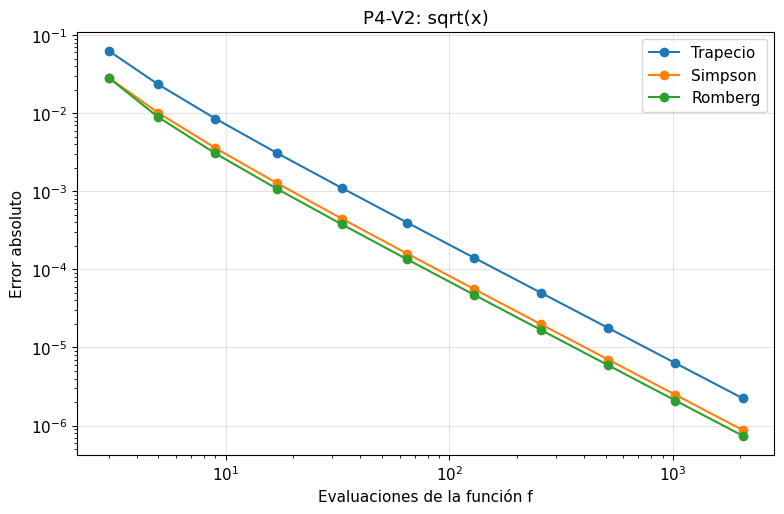

Caso exp(cos(x))
n   errT   errS   errR
2 1.7405e+00 7.2080e-01 7.2080e-01
4 3.4397e-02 5.3432e-01 5.2188e-01
8 1.2517e-06 1.1464e-02 3.2048e-02
16 8.8818e-16 4.1723e-07 2.8054e-04
32 1.7764e-15 8.8818e-16 1.4018e-05
64 0.0000e+00 8.8818e-16 6.3897e-08
128 2.6645e-15 8.8818e-16 6.2880e-11
256 1.7764e-15 8.8818e-16 1.3323e-14
512 0.0000e+00 8.8818e-16 0.0000e+00
1024 1.7764e-15 8.8818e-16 0.0000e+00
2048 0.0000e+00 8.8818e-16 0.0000e+00
Órdenes a partir de las primeras cuatro mallas:
Trapecio [np.float64(5.661), np.float64(14.746), nan]
Simpson [np.float64(0.432), np.float64(5.543), np.float64(14.746)]
Romberg [np.float64(0.466), np.float64(4.025), np.float64(6.836)]


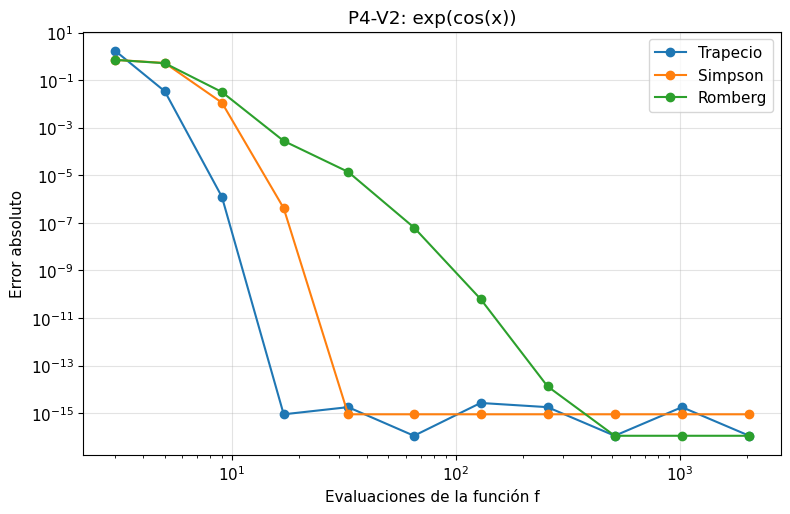

V3: integración y mínima energía
Integral exacta de Runge: 0.5493603067780064 energía de f: 294.51088373665715
  n       int S       int Simpson       error S      error Simpson     Simpson(S)-intS      E(S)      E(f)      E(L)
   6   0.58199122      0.64403301   3.263e-02     9.467e-02         0.000e+00   1.674e+02   2.945e+02   3.441e+03
  12   0.55007506      0.54036028   7.148e-04     9.000e-03         0.000e+00   2.904e+02   2.945e+02   1.879e+06
  24   0.54936656      0.54913762   6.258e-06     2.227e-04         0.000e+00   2.925e+02   2.945e+02   1.310e+11
Condiciones naturales verificadas: M0=Mn=0 en todos los casos.


In [20]:

def trapecio_compuesto(f, a, b, n):
    """Regla del trapecio compuesta con n subintervalos."""
    if n < 1:
        raise ValueError('n debe ser positivo')
    x = np.linspace(a, b, n+1)
    y = f(x)
    return (b-a)/n * ((y[0]+y[-1])/2 + np.sum(y[1:-1]))


def simpson_compuesto(f, a, b, n):
    """Regla de Simpson compuesta con n par."""
    if n < 2 or n % 2 != 0:
        raise ValueError('Simpson requiere n par >= 2')
    x = np.linspace(a, b, n+1)
    y = f(x)
    return (b-a)/(3*n) * (y[0]+y[-1]
                             + 4*np.sum(y[1:-1:2])
                             + 2*np.sum(y[2:-1:2]))


def romberg(f, a, b, m):
    """Tabla de Romberg reutilizando extremos y solo evaluando nodos nuevos."""
    if m < 1:
        raise ValueError('m debe ser positivo')
    R = np.full((m, m), np.nan)
    R[0, 0] = (b-a)*(f(a)+f(b))/2
    for i in range(1, m):
        h = (b-a) / (2**i)
        impares = a + h * np.arange(1, 2**i, 2)
        R[i, 0] = R[i-1, 0]/2 + h*np.sum(f(impares))
        for j in range(1, i+1):
            R[i, j] = R[i, j-1] + (R[i, j-1]-R[i-1, j-1])/(4**j-1)
    return R


def orden_observado(err_grueso, err_fino):
    """Estimación de orden si los dos errores son confiables."""
    if err_grueso <= 1e-14 or err_fino <= 1e-14:
        return np.nan
    return np.log2(err_grueso/err_fino)


print('V1: sin(x) en [0, pi]')
fc = ContadorEvaluaciones(np.sin)
Rsin = romberg(fc, 0, np.pi, 4)
print('Número de evaluaciones para 4 filas:', fc.n, '(esperado: 9)')
for i in range(4):
    print('Fila', i, ':',
          '  '.join(f'{Rsin[i,j]:.9f}' for j in range(i+1)))
print('Valores pedidos: R[1,0], R[2,0], R[3,0], R[2,1], R[3,1], R[3,2]')
print([round(Rsin[i,j], 6) for i,j in [(1,0),(2,0),(3,0),(2,1),(3,1),(3,2)]])
Rsin_ext = romberg(ContadorEvaluaciones(np.sin), 0, np.pi, 9)
for j in range(4):
    errs = [abs(Rsin_ext[i,j]-2) for i in range(j,9)]
    pares = [orden_observado(errs[i],errs[i+1]) for i in range(len(errs)-1)]
    print(f'Romberg seno, col {j} órdenes:', np.round(pares[:5], 3))

print('P4-V1: costo de evaluaciones frente a error en exp(x)')
real_exp = np.e - 1
costop4, errores_t, errores_s, errores_r = [], [], [], []
print('   n  evaluaciones  err trapecio     err Simpson     err Romberg')
for k in range(1, 10):
    n = 2**k
    ft = ContadorEvaluaciones(np.exp)
    fs = ContadorEvaluaciones(np.exp)
    fr = ContadorEvaluaciones(np.exp)
    v_t = trapecio_compuesto(ft, 0, 1, n)
    v_s = simpson_compuesto(fs, 0, 1, n)
    v_r = romberg(fr, 0, 1, k+1)[-1,-1]
    et, es, er = abs(v_t-real_exp), abs(v_s-real_exp), abs(v_r-real_exp)
    costop4.append(fr.n)
    errores_t.append(et)
    errores_s.append(es)
    errores_r.append(er)
    print(f'{n:4d} {fr.n:12d} {et:15.6e} {es:15.6e} {er:15.6e}')
    if ft.n != n+1 or fs.n != n+1 or fr.n != n+1:
        raise AssertionError('Conteo incorrecto de evaluaciones')
plt.figure()
for errores, nombre in ((errores_t,'Trapecio'),(errores_s,'Simpson'),(errores_r,'Romberg')):
    plt.loglog(costop4, np.maximum(errores,U), 'o-', label=nombre)
plt.xlabel('Número total de evaluaciones de f')
plt.ylabel('Error absoluto')
plt.title('P4-V1: costo y precisión para integral exp(x)')
plt.legend()
plt.show()

print('V2: falta de suavidad vs periodicidad')

termino = 1.0
bessel_i0 = termino
for k in range(1, 45):
    termino = termino / (4*k*k)
    bessel_i0 += termino
real_periodica = 2*np.pi*bessel_i0
print('Integral periódica de referencia:', real_periodica)
casosp4 = [
    ('sqrt(x)', lambda x: np.sqrt(x), 0., 1., 2/3),
    ('exp(cos(x))', lambda x: np.exp(np.cos(x)), 0., 2*np.pi, real_periodica),
]
for titulo, f, aa, bb, exacta in casosp4:
    ns = [2**k for k in range(1, 12)]
    errores = {'Trapecio':[], 'Simpson':[], 'Romberg':[]}
    for k, n in enumerate(ns, 1):
        errores['Trapecio'].append(abs(trapecio_compuesto(ContadorEvaluaciones(f),aa,bb,n)-exacta))
        errores['Simpson'].append(abs(simpson_compuesto(ContadorEvaluaciones(f),aa,bb,n)-exacta))
        errores['Romberg'].append(abs(romberg(ContadorEvaluaciones(f),aa,bb,k+1)[-1,-1]-exacta))
    print('Caso', titulo)
    print('n   errT   errS   errR')
    for i,n in enumerate(ns):
        print(n, *[f'{errores[m][i]:.4e}' for m in errores])
    print('Órdenes a partir de las primeras cuatro mallas:')
    for m in errores:
        print(m, [round(orden_observado(errores[m][j],errores[m][j+1]),3) for j in range(3)])
    plt.figure()
    for m in errores:
        plt.loglog(np.array(ns)+1,np.maximum(errores[m], U), 'o-', label=m)
    plt.xlabel('Evaluaciones de la función f')
    plt.ylabel('Error absoluto')
    plt.title('P4-V2: '+titulo)
    plt.legend()
    plt.show()

print('V3: integración y mínima energía')
int_runge = 2*np.arctan(5)/5
malla_energy = np.linspace(-1,1,4001)
h_energy = malla_energy[1]-malla_energy[0]

def simpson_valores(valores, paso):
    """Integral de Simpson de 4000 subintervalos para valores tabulados."""
    return paso/3*(valores[0]+valores[-1]
                   +4*np.sum(valores[1:-1:2])+2*np.sum(valores[2:-1:2]))

energia_real = simpson_valores(d2runge(malla_energy)**2,h_energy)
print('Integral exacta de Runge:',int_runge,'energía de f:',energia_real)
print('  n       int S       int Simpson       error S      error Simpson'
      '     Simpson(S)-intS      E(S)      E(f)      E(L)')
for n in (6,12,24):
    xx = np.linspace(-1,1,n+1)
    yy = runge(xx)
    hh = np.diff(xx)
    Mi = spline_natural(xx, yy)
    int_s = np.sum(hh*(yy[:-1]+yy[1:])/2 - hh**3*(Mi[:-1]+Mi[1:])/24)
    int_sim = simpson_compuesto(ContadorEvaluaciones(runge),-1,1,n)
    medios = (xx[:-1]+xx[1:])/2
    int_s_sim = np.sum(hh/6*(yy[:-1]+4*evaluar_spline(xx, yy, Mi, medios)+yy[1:]))
    energia_s = np.sum(hh/3*(Mi[:-1]**2+Mi[:-1]*Mi[1:]+Mi[1:]**2))

    hd = 2e-4
    segunda_L = segunda_central(lambda z: lagrange(xx, yy, z), malla_energy, hd)
    energia_l = simpson_valores(segunda_L**2, h_energy)
    print(f'{n:4d} {int_s:12.8f} {int_sim:15.8f} {abs(int_s-int_runge):11.3e}'
          f' {abs(int_sim-int_runge):13.3e} {abs(int_s_sim-int_s):17.3e}'
          f' {energia_s:11.3e} {energia_real:11.3e} {energia_l:11.3e}')
print('Condiciones naturales verificadas: M0=Mn=0 en todos los casos.')


### **Conclusiones del Problema 4**

**V1:** Para

$$\int_0^\pi\sin x\,dx=2,$$

se encontraron los trapecios $T_2\approx1.570796$, $T_4\approx1.896119$ y $T_8\approx1.974232$. Las extrapolaciones produjeron aproximadamente $2.004560$, $2.000269$ y $1.999983$ al redondear a seis decimales. En una función suave como $e^x$, el error de Romberg llegó luego de 17 evaluaciones al orden de $10^{-14}$ y al entorno de la precisión de máquina con alrededor de 33 evaluaciones. Esta mejora viene de eliminar los sucesivos términos pares del error de trapecio.

El algoritmo conserva las evaluaciones ya realizadas y, al duplicar el número de subintervalos, solo calcula los nuevos puntos medios. Con $m$ filas se necesitan en total $2^{m-1}+1$ valores de $f$, no la suma independiente de todas las filas. Debido a esto la tabla de Romberg aprovecha la información previa.

**V2:** Para $f(x)=\sqrt{x}$ sobre $[0,1]$ se conoce la integral exacta $2/3$, pero $f'(x)=1/(2\sqrt{x})$ es no acotada cuando $x\to0^+$. La hipótesis $C^1$ falla en el extremo. El error muestra un orden cercano a $1.5$, esto aplica tambien para Simpson y Romberg, pues no se dispone de la serie usual en potencias pares cuyo término inicial puedan eliminar las extrapolaciones.

Para $f(x)=e^{\cos x}$ en $[0,2\pi]$, el valor de referencia es aproximadamente $7.954926521013$. Esta función es analítica y periódica, así que las derivadas de los extremos coinciden. En Euler–Maclaurin esto anula los términos de borde $f^{(2k-1)}(b)-f^{(2k-1)}(a)$, el trapecio puede ser muy preciso con pocos subintervalos. En la prueba realizada llegó al entorno de precisión de máquina con $n=16$, por lo que todos los niveles no son necesariamente mejorados por Romberg.

**V3:** La integral de Runge en $[-1,1]$ es

$$\int_{-1}^1\frac{dx}{1+25x^2}=\frac25\arctan5\approx0.549360306778.$$

Con 24 subintervalos, el error de integrar el spline natural fue cercano a $6.26\times10^{-6}$, frente al aproximadamente $2.23\times10^{-4}$ al aplicar Simpson compuesto directamente a los datos. La integral de cada tramo del spline se obtiene exactamente por su expresión cúbica, Simpson también la reproduce si se aplica dentro de cada tramo incluyendo al punto medio.

La energía del spline fue aproximadamente $2.925\times10^2$, frente a $2.945\times10^2$ para la función Runge y alrededor de $1.31\times10^{11}$ para el polinomio global de Lagrange, este último fue como estimación numérica sensible al paso elegido para la segunda derivada. La desigualdad de mínima energía se justifica expandiendo $g=S+v$ e integrando por partes, todos los términos cruzados se cancelan en los nodos y desaparecen en los extremos gracias a las condiciones naturales $S''(a)=S''(b)=0$.

En conclusión, las reglas de un orden alto dependen de las hipótesis de suavidad, no solamente de su fórmula. En este caso, la integración por spline resultó ser precisa y su energía de curvatura fue menor que la de otros interpolantes, esto de acuerdo con la propiedad del spline natural.

---
## Entregables exigidos

El informe (este notebook ejecutado, exportado a PDF o HTML) debe contener:
1. **Demostraciones** T1 y T2 de cada problema, en Markdown con LaTeX, citando los resultados usados.
2. **Código** de todas las rutinas de implementación, documentado y sin funciones prohibidas.
3. **Tablas** de cada validación (errores, cotas, cocientes, órdenes empíricos, conteos de operaciones y evaluaciones).
4. **Gráficas**: P1-V1 (semilog), P2-V1, P2-V3, P3-V1, P3-V2, P4-V1 y P4-V2 (log–log), P2-V2 (interpolantes de Runge).
5. **Discusión** por problema que compare cada predicción teórica con la evidencia y explique toda discrepancia (redondeo, hipótesis no satisfechas, resolución de los datos).
6. Si trabaja en pareja, los nombres de ambos integrantes en la primera celda.

---
## Fuentes principales consultadas
* Carrillo E., J. C. *Análisis Numérico*, notas de clase: AN-LN-3-1, AN-LN-3-3 y AN-LN-3-4 (interpolación y aproximación); AN-4.1 y AN-4.2 (derivada e integral numérica). Escuela de Matemáticas, UIS.
* Burden, R. L., Faires, J. D. y Burden, A. M. (2016). *Análisis numérico* (10.ª ed.). Cengage Learning. §3.1, 3.3–3.5; §4.1–4.5; §6.6 (sistemas tridiagonales).
* Süli, E. y Mayers, D. F. (2003). *An Introduction to Numerical Analysis*. Cambridge University Press. Caps. 6 y 7.
* Kincaid, D. y Cheney, W. (2002). *Numerical Analysis: Mathematics of Scientific Computing* (3.ª ed.). AMS. Caps. 6 y 7.
* Atkinson, K. E. (1989). *An Introduction to Numerical Analysis* (2.ª ed.). Wiley. Caps. 3 y 5 (fórmula de Euler–Maclaurin).
* Golub, G. H. y Van Loan, C. F. (2013). *Matrix Computations* (4.ª ed.). Johns Hopkins University Press. §4.3.
* de Boor, C. (2001). *A Practical Guide to Splines* (ed. rev.). Springer.
* Richardson, L. F. (1911). The approximate arithmetical solution by finite differences of physical problems. *Phil. Trans. R. Soc. A*, 210, 307–357.
* Romberg, W. (1955). Vereinfachte numerische Integration. *Det Kongelige Norske Videnskabers Selskab Forhandlinger*, 28, 30–36.
* Navot, I. (1961). An extension of the Euler–Maclaurin summation formula to functions with a branch singularity. *Journal of Mathematics and Physics*, 40, 271–276.
* Trefethen, L. N. y Weideman, J. A. C. (2014). The exponentially convergent trapezoidal rule. *SIAM Review*, 56(3), 385–458.
* Higham, N. J. (2002). *Accuracy and Stability of Numerical Algorithms* (2.ª ed.). SIAM.
* Documentación oficial: NumPy (https://numpy.org/doc/stable/) y Matplotlib (https://matplotlib.org/stable/).

---
## Rúbrica de evaluación (escala 0.0–5.0)

Alineada con la Taxonomía TSP (SOLO Plus). La nota es el promedio ponderado de los cuatro criterios.

| Criterio | Abstracto / Abstracto extendido (NA/NAE) <br> **4.5–5.0** | Relacional (NR) <br> **4.0–4.4** | Multiestructural (NM) <br> **3.5–3.9** | Uniestructural / Preestructural (NU/NP) <br> **< 3.5** |
| :--- | :--- | :--- | :--- | :--- |
| **1. Fundamentación teórica (25 %)** | Las ocho demostraciones son completas y rigurosas, con hipótesis explícitas y citas precisas: cota de $\Psi_n$, identidad $e_n-\hat e_n=f-p_{n+1}$, sistema en $M_i$ y dominancia diagonal, Thomas por inducción con conteo $8n-7$, derivación por límite, constante $h^4/480$, error de Simpson vía Hermite y orden de Romberg. Señala el papel de cada hipótesis. | Demostraciones correctas con omisiones menores de rigor (p. ej. no justifica el valor intermedio o el signo de $w$). | Enuncia los resultados y realiza cálculos parciales; algunas demostraciones son incompletas o tienen errores algebraicos. | Faltan demostraciones o se sustituyen por verificaciones numéricas. |
| **2. Implementación (20 %)** | Todas las rutinas son correctas, vectorizadas donde procede, documentadas (PEP 8, *docstrings*, fundamento matemático) y sin funciones prohibidas; Thomas y Romberg reutilizan la estructura (costo $O(n)$, evaluaciones reutilizadas). | Rutinas correctas con documentación o eficiencia mejorables. | Errores menores (índices, casos de frontera) que exigen ajustes manuales. | Rutinas ausentes, incorrectas o que usan solucionadores o bibliotecas prohibidas. |
| **3. Validación empírica (30 %)** | Las diez validaciones están completas; los órdenes, cotas y constantes se estiman en el régimen asintótico y se contrastan explícitamente con la teoría y con las notas; explica la saturación por redondeo, el efecto de frontera del spline natural y la falla de las hipótesis de Romberg. | Validaciones completas con interpretación correcta pero poco profunda de alguna discrepancia. | Falta alguna validación, o los órdenes se estiman en la zona de redondeo sin advertirlo. | Las validaciones no permiten contrastar la teoría o son inconsistentes con el código. |
| **4. Presentación y discusión (25 %)** | Tablas y gráficas con formato académico (ejes, escalas log, leyendas); discusión propia que sintetiza teoría y evidencia y explica cada discrepancia con argumentos cuantitativos. | Entregables completos y legibles; discusión correcta pero descriptiva. | Gráficas o tablas con defectos de formato; discusión superficial. | Faltan entregables; discusión ausente, errónea o no propia. |